# Feature Integration and Model Improvement

## 1. Introduction

This notebook extends the baseline regression models developed in `05_baseline_models.ipynb` by incorporating additional property characteristics, amenities, and geospatial features developed in the preceding data analysis notebooks.

The baseline analysis evaluated five regression models using eight predictor variables. Histogram-based Gradient Boosting achieved the best validation performance, with an MAE of $229.22, RMSE of $396.24, $R^2$ of 0.8331, and Median Absolute Percentage Error (MdAPE) of 8.52%.

The objective of this notebook is to evaluate the incremental predictive contribution of additional feature groups through three experiments:

1. **Property Characteristics and Amenities:** Incorporate additional categorical variables and amenity indicators developed in Notebook 03.
2. **Geospatial Features:** Evaluate geographic variables developed in Notebook 04, independently of the additional property characteristics and amenities.
3. **Combined Features:** Evaluate the predictive performance of both feature groups together.

The experiments will use Histogram-based Gradient Boosting as the primary regression model, maintaining the baseline model configuration wherever possible to isolate the contribution of the additional features.

All experiments will preserve the group-aware train-validation-test splitting strategy based on `uru_id`, ensuring that observations from the same rental unit do not appear in different subsets. The test set will remain reserved for final model evaluation.

Predictive performance will be evaluated using MAE, RMSE, $R^2$, and MdAPE.

The results will help determine whether additional property information and geographic context improve rental price predictions beyond the baseline model.


## 2. Data Loading and Validation

This section establishes the data foundation for the feature integration experiments.

We begin by loading the prepared Chicago rental listings dataset used in the baseline modeling notebook. Additional features developed in Notebooks 03 and 04 will be incorporated and validated before model training.

To ensure a fair comparison with the baseline results, we will:

1. Preserve the original target variable (`rent_amount`) and rental unit identifier (`uru_id`).
2. Maintain the same observations and group-aware train-validation-test partitions used in the baseline experiments.
3. Examine the availability, completeness, and consistency of the additional features.
4. Check for potential data leakage before incorporating new predictors.

The reserved test set will not be used for model selection or feature evaluation.


In [6]:
import numpy as np
import pandas as pd

from pathlib import Path

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.base import BaseEstimator, TransformerMixin

# Reproducibility
seed = 710


# Data paths
DATA_DIR = Path("../../../data/processed")
BASELINE_DATA_PATH = DATA_DIR / "chicago_prepared_full.csv"

# Verify file location
print(f"Dataset found: {BASELINE_DATA_PATH.exists()}")


Dataset found: True


In [7]:
# Load the prepared Chicago rental listings dataset
df = pd.read_csv(BASELINE_DATA_PATH)

# Check dataset dimensions
print(f"Number of observations: {df.shape[0]:,}")
print(f"Number of variables: {df.shape[1]}")

# Check rental unit identifiers
print(f"Unique rental units: {df['uru_id'].nunique():,}")

# Check target variable
print(f"Missing rental prices: {df['rent_amount'].isna().sum():,}")
print(f"Missing rental unit IDs: {df['uru_id'].isna().sum():,}")


Number of observations: 545,312
Number of variables: 49
Unique rental units: 152,233
Missing rental prices: 0
Missing rental unit IDs: 0


## 3. Train-Validation-Test Split

To ensure comparability with the baseline models, we reproduce the same group-aware train-validation-test split used in `05_baseline_models.ipynb`.

Observations are grouped by `uru_id` to prevent rental units with multiple observations from appearing in different subsets.

We use `GroupShuffleSplit` with the same random seed and splitting proportions as in the baseline analysis.

The resulting training and validation sets will be used for feature integration experiments, while the test set will remain reserved for final model evaluation.


In [8]:
# Define the same baseline features used in Notebook 05
numerical_features = [
    "bedrooms",
    "full_baths",
    "square_feet",
    "year_built",
    "listing_year",
    "listing_month"
]

categorical_features = [
    "address_zip",
    "uru_type"
]

baseline_features = numerical_features + categorical_features

# Define predictors, target, and grouping variable
X = df[baseline_features].copy()
y = df["rent_amount"].copy()
groups = df["uru_id"].copy()

print("Predictor matrix:", X.shape)
print("Target observations:", len(y))
print("Unique rental units:", groups.nunique())


Predictor matrix: (545312, 8)
Target observations: 545312
Unique rental units: 152233


In [9]:
# First split: development and test sets
test_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=seed
)

dev_idx, test_idx = next(
    test_splitter.split(X, y, groups=groups)
)

X_dev = X.iloc[dev_idx].copy()
X_test = X.iloc[test_idx].copy()

y_dev = y.iloc[dev_idx].copy()
y_test = y.iloc[test_idx].copy()

groups_dev = groups.iloc[dev_idx].copy()
groups_test = groups.iloc[test_idx].copy()

# Second split: training and validation sets
val_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=seed
)

train_idx, val_idx = next(
    val_splitter.split(X_dev, y_dev, groups=groups_dev)
)

X_train = X_dev.iloc[train_idx].copy()
X_val = X_dev.iloc[val_idx].copy()

y_train = y_dev.iloc[train_idx].copy()
y_val = y_dev.iloc[val_idx].copy()

groups_train = groups_dev.iloc[train_idx].copy()
groups_val = groups_dev.iloc[val_idx].copy()

# Verify that rental units do not overlap
train_units = set(groups_train)
val_units = set(groups_val)
test_units = set(groups_test)

assert train_units.isdisjoint(val_units)
assert train_units.isdisjoint(test_units)
assert val_units.isdisjoint(test_units)

# Display split summary
print("Training observations:", len(X_train))
print("Validation observations:", len(X_val))
print("Test observations:", len(X_test))

print("\nTraining units:", len(train_units))
print("Validation units:", len(val_units))
print("Test units:", len(test_units))

print("\nTraining proportion:", round(len(X_train) / len(X), 4))
print("Validation proportion:", round(len(X_val) / len(X), 4))
print("Test proportion:", round(len(X_test) / len(X), 4))

print("\nNo overlapping rental units across splits.")


Training observations: 348494
Validation observations: 87942
Test observations: 108876

Training units: 97428
Validation units: 24358
Test units: 30447

Training proportion: 0.6391
Validation proportion: 0.1613
Test proportion: 0.1997

No overlapping rental units across splits.


## 4. Experiment 1: Property Characteristics and Amenities

The first experiment evaluates whether additional property characteristics and amenity indicators improve rental price predictions beyond the eight baseline features.

We begin by identifying the relevant variables developed or examined in Notebook 03 and verifying their availability in the modeling dataset.

After validating these features, we will extend the baseline predictor set and retrain four regression models: Linear Regression, Decision Tree, Random Forest, and Histogram-based Gradient Boosting.

All models will use the same training and validation partitions as in Notebook 05, retaining their original hyperparameter configurations wherever possible.

The objective is to evaluate the predictive contribution of additional property characteristics and amenities, while examining how different regression algorithms benefit from these features.

Performance will be assessed using MAE, RMSE, $R^2$, and MdAPE, and compared against the corresponding baseline results.


In [11]:
# Summarize additional variables
additional_summary = pd.DataFrame({
    "Variable": additional_columns,
    "Data Type": [
        str(df[col].dtype) for col in additional_columns
    ],
    "Missing (%)": [
        df[col].isna().mean() * 100
        for col in additional_columns
    ],
    "Unique Values": [
        df[col].nunique(dropna=True)
        for col in additional_columns
    ]
})

# Display all additional variables
with pd.option_context("display.max_rows", None):
    display(
        additional_summary.style.format({
            "Missing (%)": "{:.2f}"
        })
    )


,Variable,Data Type,Missing (%),Unique Values
0,dwellsy_address_id,str,0.00,152233
1,address1_id,int64,0.00,54426
2,address2_id,float64,9.55,129723
3,data_source_external_id,int64,0.00,277603
4,listing_id,int64,0.00,545312
5,community_id,int64,0.00,41953
6,community_name,str,0.00,41926
7,company_name,str,0.00,13141
8,top_down_community_count,int64,0.00,460
9,top_down_address1_count,int64,0.00,427


In [12]:
# Inspect the structure of the amenities variable
print("Examples of non-missing amenities values:\n")

for i, value in enumerate(df["amenities"].dropna().head(5), start=1):
    print(f"Example {i}:")
    print(str(value)[:500])
    print()


Examples of non-missing amenities values:

Example 1:
12 Month Lease or Longer; Cable Ready; Cats OK; Gas included in rent; Hardwood or Hardwood Look Floors; Intercom; Large Dogs OK; Range/Cooktop/Oven; Refrigerator; Small Dogs OK; Trash service included in rent; Water included in rent; Yard/Lawn

Example 2:
12 Month Lease or Longer; Air Conditioning; Cable Ready; Cats OK; Central Heat; Dishwasher; Gym/Fitness Center; Hardwood or Hardwood Look Floors; Intercom; Large Dogs OK; Microwave; Range/Cooktop/Oven; Refrigerator; Small Dogs OK; Washer & Dryer In Home

Example 3:
Bike Storage; Cats OK; Deck/Porch/Patio; Elevator; Gym/Fitness Center; Internet included in rent; Large Dogs OK; Medium Dogs OK; Microwave; Package Receiving; Pet Restrictions May Apply; Refrigerator; Sewage included in rent; Small Dogs OK; Smart Home; Trash service included in rent; Washer & Dryer On-Site; Water included in rent; WiFi/High-Speed Internet Available

Example 4:
Bike Storage; Cats OK; Deck/Porch/Patio; Ele

### 4.1. Loading and Validating Amenity Features

Notebook 03 transformed the original `amenities` variable into 260 binary indicators representing property characteristics and amenities. These features were exported into separate datasets for Chicago and Washington, D.C., using `listing_id` as the unique identifier.

For the current experiment, we will load the Chicago amenity features from `chicago_amenity_features.csv` and integrate them with the baseline modeling dataset.

Before merging the datasets, we will verify that:

1. The amenity dataset contains the expected number of observations and features.
2. `listing_id` contains no missing or duplicated values.
3. All listing identifiers match those in the baseline modeling dataset.

These checks will ensure that the additional features can be incorporated without introducing duplicate observations or excluding existing listings.

The original train-validation-test partitions will be preserved to ensure comparability with the baseline models developed in Notebook 05.


In [13]:
# Load amenity features generated in Notebook 03
AMENITIES_PATH = DATA_DIR / "chicago_amenity_features.csv"

df_amenities = pd.read_csv(AMENITIES_PATH)

print("Amenity dataset shape:", df_amenities.shape)

# Validate merge key
print("Missing listing_id:",
      df_amenities["listing_id"].isna().sum())

print("Duplicated listing_id:",
      df_amenities["listing_id"].duplicated().sum())

# Compare listing identifiers across datasets
baseline_ids = set(df["listing_id"])
amenity_ids = set(df_amenities["listing_id"])

print("\nListings missing from amenity dataset:",
      len(baseline_ids - amenity_ids))

print("Additional listings in amenity dataset:",
      len(amenity_ids - baseline_ids))


Amenity dataset shape: (545312, 261)
Missing listing_id: 0
Duplicated listing_id: 0

Listings missing from amenity dataset: 0
Additional listings in amenity dataset: 0


In [14]:
# Merge baseline data with amenity features
df_enriched = df.merge(
    df_amenities,
    on="listing_id",
    how="left",
    validate="one_to_one",
    sort=False
)

# Validate the merged dataset
print("Original dataset shape:", df.shape)
print("Enriched dataset shape:", df_enriched.shape)

amenity_cols = [
    col for col in df_amenities.columns
    if col != "listing_id"
]

print("\nNumber of amenity features:", len(amenity_cols))
print("Missing amenity values:",
      df_enriched[amenity_cols].isna().sum().sum())

# Verify that original observations and their order are preserved
assert len(df_enriched) == len(df)
assert df_enriched["listing_id"].equals(
    df["listing_id"].reset_index(drop=True)
)
assert df_enriched["uru_id"].equals(
    df["uru_id"].reset_index(drop=True)
)
assert df_enriched["rent_amount"].equals(
    df["rent_amount"].reset_index(drop=True)
)

print("\nAll original observations and their order are preserved.")


Original dataset shape: (545312, 49)
Enriched dataset shape: (545312, 309)

Number of amenity features: 260
Missing amenity values: 0

All original observations and their order are preserved.


### 4.2. Exploring Amenity Features

After successfully integrating the 260 binary amenity indicators, we examine their distributions before incorporating them into the regression models.

This exploratory analysis will help identify features that are constant across observations, amenities that occur infrequently, and the most prevalent property characteristics.

Understanding the distribution of these indicators will inform our feature selection strategy and help ensure that the additional predictors provide meaningful information for rental price estimation.

Any feature selection informed by the target variable or model performance will be conducted using only the training data to avoid data leakage.


In [15]:
# Summarize amenity feature distributions
amenity_summary = pd.DataFrame({
    "Prevalence (%)": df_enriched[amenity_cols].mean() * 100,
    "Unique values": df_enriched[amenity_cols].nunique()
})

amenity_summary = amenity_summary.sort_values(
    "Prevalence (%)", ascending=False
)

print("Total amenity features:", len(amenity_cols))
print("Constant features:",
      (amenity_summary["Unique values"] == 1).sum())

print("\nMost prevalent amenities:")
display(amenity_summary.head(15).round(2))

print("\nLeast prevalent amenities:")
display(amenity_summary.tail(15).round(2))


Total amenity features: 260
Constant features: 9

Most prevalent amenities:


,Prevalence (%),Unique values
amenity_Cats OK,71.27,2
amenity_Small Dogs OK,58.70,2
amenity_Large Dogs OK,54.36,2
amenity_Hardwood or Hardwood Look Floors,48.36,2
amenity_Dishwasher,48.06,2
amenity_Pet Restrictions May Apply,47.21,2
amenity_Refrigerator,42.39,2
amenity_Water included in rent,42.22,2
amenity_Range/Cooktop/Oven,37.05,2
amenity_Washer & Dryer On-Site,34.85,2



Least prevalent amenities:


,Prevalence (%),Unique values
amenity_Arched Windows,0.0,2
amenity_Mirrored,0.0,2
amenity_Dog Walking,0.0,2
amenity_Washer & Dryer In Unit,0.0,2
amenity_Pool service included in rent,0.0,2
amenity_Premium Cabinets,0.0,2
amenity_Transome Windows,0.0,1
amenity_Efficient Water,0.0,1
amenity_Oil Heat,0.0,1
amenity_Personal Trainer,0.0,1


#### 4.2.1. Amenity Encoding and Validation

Before evaluating the predictive contribution of the amenity features, we verify that the 260 indicators generated in Notebook 03 are correctly encoded and suitable for regression modeling.

Each amenity should be represented as a binary variable:

- **1:** The amenity is reported in the rental listing.
- **0:** The amenity is not reported in the rental listing.

We examine the data types, unique values, and prevalence of these indicators to confirm their consistency and identify the most commonly reported amenities.

The validation confirms that:

- All 260 amenity indicators are stored as integers (`int64`).
- All indicators contain exclusively binary values (0 and 1).
- No missing values are present.
- Amenity prevalence ranges from 0% to approximately 71.27%.

The most frequently reported amenities include pet-related policies, hardwood flooring, dishwashers, and other common property characteristics.

These findings confirm that the engineered amenity features are correctly encoded and can be considered for subsequent predictive modeling.

Importantly, amenity prevalence measures how frequently a characteristic appears in rental listings, not how strongly it is associated with rental prices. The latter will be examined separately using training-set observations only.


In [16]:
# Validate amenity feature types and values
print("Amenity data types:")
print(df_enriched[amenity_cols].dtypes.value_counts())

# Inspect the distinct values across amenity indicators
unique_values = pd.unique(
    df_enriched[amenity_cols].to_numpy().ravel()
)

print("\nUnique amenity values:", unique_values)

# Check whether all indicators are binary
binary_check = df_enriched[amenity_cols].isin([0, 1]).all().all()

print("All amenity features are binary:", binary_check)

# Examine prevalence without rounding
amenity_prevalence = df_enriched[amenity_cols].mean() * 100

print("\nPrevalence range (%):")
print("Minimum:", amenity_prevalence.min())
print("Maximum:", amenity_prevalence.max())

print("\nTop 10 most prevalent amenities:")
display(
    amenity_prevalence
    .sort_values(ascending=False)
    .head(10)
    .to_frame("Prevalence (%)")
)


Amenity data types:
int64    260
Name: count, dtype: int64

Unique amenity values: [0 1]
All amenity features are binary: True

Prevalence range (%):
Minimum: 0.0
Maximum: 71.26965847074702

Top 10 most prevalent amenities:


,Prevalence (%)
amenity_Cats OK,71.269658
amenity_Small Dogs OK,58.699974
amenity_Large Dogs OK,54.356955
amenity_Hardwood or Hardwood Look Floors,48.364239
amenity_Dishwasher,48.063311
amenity_Pet Restrictions May Apply,47.214989
amenity_Refrigerator,42.392429
amenity_Water included in rent,42.224085
amenity_Range/Cooktop/Oven,37.050716
amenity_Washer & Dryer On-Site,34.854725


#### 4.2.2 Amenity Prevalence in the Training Set

The 260 amenity indicators were successfully validated as binary variables, containing only values of 0 and 1, with no missing values. Their prevalence across the Chicago dataset ranges from 0% to approximately 71.27%.

Before evaluating their relationship with rental prices, we examine the distribution of these features within the training set.

This analysis focuses on identifying:

1. **Constant features:** Amenities with no variation across training observations. These features cannot distinguish between rental listings within the training data and therefore provide no useful predictive information.
2. **Rare features:** Amenities appearing in fewer than 1% of training observations. Their associations with rental prices may be unstable because relatively few observations contain these characteristics.
3. **Potentially informative features:** Amenities with sufficient variation to support further analysis of their relationship with rental prices.

The 1% prevalence threshold is used for exploratory purposes and does not represent a final feature selection decision. Rare amenities may still contain valuable predictive information.

All calculations are restricted to the training set to ensure that subsequent feature selection decisions remain independent of the validation and test datasets.

The results will help determine which amenity indicators should be considered in the next stage of feature selection, where their associations with `rent_amount` will be evaluated.


In [17]:
# Restrict amenity analysis to training observations
train_amenities = df_enriched.loc[X_train.index, amenity_cols]

# Calculate amenity prevalence in the training set
train_prevalence = train_amenities.mean()

# Identify constant and rare features
constant_amenities = train_prevalence[
    (train_prevalence == 0) | (train_prevalence == 1)
].index.tolist()

rare_amenities = train_prevalence[
    (train_prevalence > 0) & (train_prevalence < 0.01)
].index.tolist()

print("Total amenity features:", len(amenity_cols))
print("Constant amenities:", len(constant_amenities))
print("Rare amenities (prevalence < 1%):", len(rare_amenities))

print("\nAmenities with prevalence >= 1% and < 100%:",
      ((train_prevalence >= 0.01) &
       (train_prevalence < 1)).sum())


Total amenity features: 260
Constant amenities: 11
Rare amenities (prevalence < 1%): 124

Amenities with prevalence >= 1% and < 100%: 125


#### 4.2.3 Training-Set Amenity Prevalence: Findings

The prevalence analysis of the 260 amenity indicators, restricted to the training set, produced the following results:

- **11 constant features (4.2%)** have no variation across training observations and therefore provide no discriminatory information.
- **124 rare features (47.7%)** occur in fewer than 1% of training observations.
- **125 features (48.1%)** have prevalence between 1% and less than 100%.

These results indicate that nearly half of the amenity indicators are relatively uncommon in the Chicago rental market.

However, low prevalence does not necessarily imply low predictive value. Certain amenities may be uncommon but strongly associated with higher or lower rental prices.

For the next stage, we will exclude the 11 constant features and retain the remaining 249 indicators as candidates for further evaluation.

Following the exploratory approach developed in Notebook 03, we will examine the relationship between individual amenities and rental prices using training-set observations only.

This approach allows us to investigate potentially informative predictors while preventing target information from the validation and test sets from influencing feature selection.


### 4.3. Amenity Associations with Rental Prices

Having examined the distribution of amenity indicators, we now investigate their relationship with rental prices.

Following the exploratory approach developed in Notebook 03, we evaluate the association between individual amenities and `rent_amount` using the following measures:

1. **Mean rent with the amenity:** Average rental price among listings reporting the amenity.
2. **Mean rent without the amenity:** Average rental price among listings not reporting the amenity.
3. **Mean rent difference:** Difference between the average rents of the two groups.
4. **Eta-squared ($\eta^2$):** The proportion of variation in rental prices associated with the binary amenity indicator.

To prevent data leakage, all calculations are restricted to the training set. The validation and test sets are excluded from this analysis.

The 11 constant amenities identified in Section 4.2 will be excluded because they provide no variation within the training data. The remaining 249 amenities will be evaluated, including rare features, whose associations should be interpreted cautiously.

Importantly, these measures describe marginal associations rather than causal effects or the incremental predictive contribution of an amenity after controlling for other property characteristics.

The results will help identify candidate features for subsequent regression experiments, where their actual predictive contribution will be assessed relative to the baseline models.


In [18]:
# Analyze amenity-rent associations using training data only
train_data = df_enriched.loc[X_train.index]

candidate_amenities = [
    col for col in amenity_cols
    if col not in constant_amenities
]

overall_mean = train_data["rent_amount"].mean()
total_ss = (
    (train_data["rent_amount"] - overall_mean) ** 2
).sum()

association_results = []

for amenity in candidate_amenities:
    grouped = train_data.groupby(amenity)["rent_amount"].agg(
        ["mean", "count"]
    )

    mean_without = grouped.loc[0, "mean"]
    mean_with = grouped.loc[1, "mean"]

    n_without = grouped.loc[0, "count"]
    n_with = grouped.loc[1, "count"]

    mean_difference = mean_with - mean_without

    between_ss = (
        n_without * (mean_without - overall_mean) ** 2
        + n_with * (mean_with - overall_mean) ** 2
    )

    eta_squared = between_ss / total_ss

    association_results.append({
        "Amenity": amenity,
        "Prevalence (%)": 100 * n_with / len(train_data),
        "Mean rent without ($)": mean_without,
        "Mean rent with ($)": mean_with,
        "Rent difference ($)": mean_difference,
        "Eta-squared": eta_squared
    })

amenity_associations = pd.DataFrame(association_results)

amenity_associations = amenity_associations.sort_values(
    "Eta-squared", ascending=False
).reset_index(drop=True)

print("Amenities evaluated:", len(amenity_associations))

print("\nTop 15 amenities by Eta-squared:")
display(amenity_associations.head(15).round(4))


Amenities evaluated: 249

Top 15 amenities by Eta-squared:


,Amenity,Prevalence (%),Mean rent without ($),Mean rent with ($),Rent difference ($),Eta-squared
0,amenity_Garage or Covered Parking,21.0348,1741.6084,2576.9091,835.3007,0.1145
1,amenity_Door Attendant,6.7456,1829.7097,3128.3715,1298.6618,0.1048
2,amenity_Pet Care/Grooming,5.8124,1838.2403,3198.6316,1360.3913,0.1001
3,amenity_Concierge,7.7468,1825.8947,3005.9684,1180.0737,0.0983
4,amenity_Guest Accomodations,5.3410,1846.3961,3174.1695,1327.7734,0.0881
5,amenity_Extra Storage,15.8143,1790.1042,2594.4882,804.3840,0.0851
6,amenity_Elevator,17.6241,1781.6915,2551.2092,769.5177,0.0849
7,amenity_Gym/Fitness Center,25.1887,1749.7973,2414.8379,665.0405,0.0823
8,amenity_EV Charging Stations,4.6933,1853.5750,3211.6103,1358.0353,0.0815
9,amenity_Theatre/Media Center,3.6156,1863.8897,3341.4628,1477.5731,0.0752


### 4.3.1. Interpretation of Amenity-Rent Associations

The association analysis evaluated 249 non-constant amenity indicators using only the training observations.

The results indicate that several amenities associated with building services, convenience, and higher-end residential properties exhibit relatively strong marginal relationships with rental prices.

**Key findings:**

- **Garage or Covered Parking** has the highest Eta-squared (0.1145), with an average rent difference of approximately $835 between listings with and without this amenity.
- **Door Attendant** and **Pet Care/Grooming** also show strong associations, with Eta-squared values of 0.1048 and 0.1001, respectively.
- **Concierge**, **Elevator**, **Gym/Fitness Center**, and **Extra Storage** are among the other amenities with relatively high association measures.
- All 15 highest-ranked amenities have prevalence above 1%, suggesting that their observed associations are not driven exclusively by extremely rare features.

These findings suggest that amenities may capture differences in building quality, services, and property characteristics that are not fully represented by the eight baseline predictors.

However, these relationships are descriptive and should not be interpreted as causal effects. Differences in location, property size, building type, and other characteristics may partially explain the observed rent differences.

Furthermore, Eta-squared measures the marginal association of each amenity with rental prices. It does not establish whether an amenity provides additional predictive information after accounting for other features.

Before selecting amenities for regression modeling, we will examine the distribution of association measures and consider potential redundancy among the strongest candidates.

The predictive contribution of the selected features will ultimately be assessed by comparing validation performance against the baseline models from Notebook 05.


### 4.3.2. Distribution of Amenity Associations

The previous analysis identified several amenities with relatively strong marginal associations with rental prices. However, examining only the 15 highest-ranked features does not reveal how association strength is distributed across all 249 candidate amenities.

In this section, we examine the distribution of Eta-squared values to determine whether a small subset of amenities accounts for most of the strongest individual associations or whether many features exhibit similar levels of association.

Specifically, we will:

1. Summarize the distribution of Eta-squared values across all candidate amenities.
2. Examine how association strength changes across the ranked features.
3. Count the number of amenities exceeding selected Eta-squared thresholds.

This analysis will inform our feature selection strategy, although the thresholds are descriptive rather than established criteria for predictive relevance.

Because Eta-squared measures marginal association, a high value does not necessarily imply that a feature provides additional predictive information after controlling for the baseline predictors.

All association measures were calculated using training observations only, preserving the independence of the validation and test datasets.


Eta-squared distribution:


,Eta-squared
count,249.000000
mean,0.012435
std,0.022392
min,0.000000
25%,0.000056
50%,0.001572
75%,0.013128
90%,0.041963
95%,0.065795
99%,0.099256



Amenities by association threshold:


,Eta-squared threshold,Number of amenities
0,0.001,134
1,0.005,98
2,0.010,71
3,0.020,50
4,0.050,20
5,0.100,3


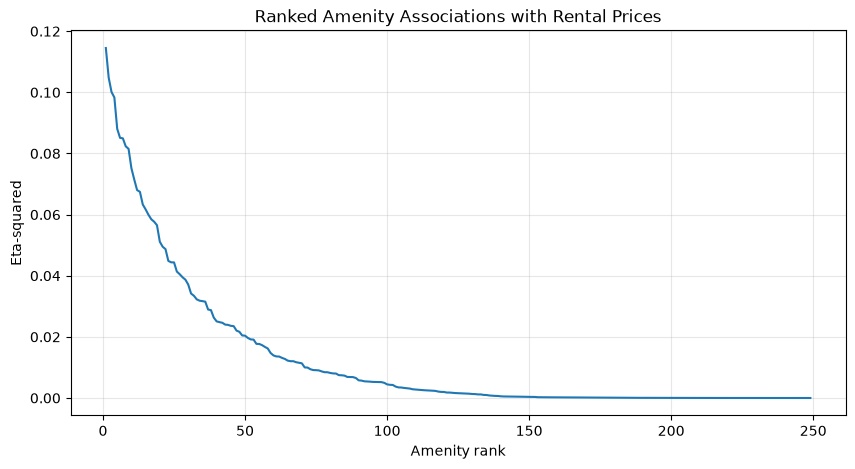

In [19]:
# Summarize the distribution of amenity associations
eta_values = amenity_associations["Eta-squared"]

print("Eta-squared distribution:")
display(
    eta_values.describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).to_frame("Eta-squared").round(6)
)

# Count amenities exceeding selected association thresholds
thresholds = [0.001, 0.005, 0.01, 0.02, 0.05, 0.10]

threshold_summary = pd.DataFrame({
    "Eta-squared threshold": thresholds,
    "Number of amenities": [
        (eta_values >= threshold).sum()
        for threshold in thresholds
    ]
})

print("\nAmenities by association threshold:")
display(threshold_summary)

# Visualize ranked association strengths
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(eta_values) + 1),
    eta_values.values
)

plt.xlabel("Amenity rank")
plt.ylabel("Eta-squared")
plt.title("Ranked Amenity Associations with Rental Prices")
plt.grid(alpha=0.3)
plt.show()


### 4.3.3. Interpretation of the Distribution of Amenity Associations

The distribution of Eta-squared values reveals substantial differences in the strength of marginal associations between amenities and rental prices.

**Key findings:**

- The maximum Eta-squared is 0.1145, while the median is only 0.0016.
- The 75th percentile is 0.0131, indicating that most amenities exhibit relatively weak individual associations with rental prices.
- Only 20 amenities have Eta-squared values of at least 0.05.
- A total of 50 amenities have Eta-squared values of at least 0.02, while 71 reach at least 0.01.
- The ranked association curve decreases sharply among the highest-ranked features and gradually approaches zero.

These findings suggest that the strongest marginal associations are concentrated in a relatively small subset of amenities.

However, low marginal association does not necessarily imply low incremental predictive value. Some amenities may become informative when combined with other property characteristics or through nonlinear relationships and interactions.

Furthermore, Eta-squared values cannot be added together to estimate the combined explanatory power of multiple amenities, as their associations with rental prices may overlap.

**Modeling decision:**

For the initial property and amenity feature experiment, we will retain all 249 non-constant amenity indicators rather than selecting variables using an arbitrary Eta-squared threshold.

This approach will allow us to evaluate the predictive contribution of the complete amenity feature set relative to the baseline models.

Subsequent experiments may investigate whether a smaller subset of amenities achieves comparable or better validation performance.

All feature decisions will remain based on training data, and the original train-validation-test partitions will be preserved.


### 4.4. Preparing the Extended Feature Set

The exploratory analysis identified 249 non-constant amenity indicators that will be incorporated into the first feature integration experiment.

We now construct an extended predictor set combining:

1. **Baseline features (8):** The six numerical and two categorical predictors used in Notebook 05.
2. **Amenity features (249):** The non-constant binary indicators generated in Notebook 03 and validated in the preceding sections.

The resulting feature set will contain 257 predictors.

To ensure a valid comparison with the baseline models, we will preserve the exact training, validation, and test observations established in Section 3.

Specifically, we will:

- Construct the extended feature matrix without modifying the original observations.
- Reuse the existing train-validation-test indices.
- Verify that the target values and rental unit identifiers remain unchanged.
- Confirm that no rental unit appears in more than one partition.
- Check the resulting matrix dimensions and missing values.

The test set will remain reserved for final evaluation and will not be used for feature selection or model comparison.

The extended feature set will subsequently be used to retrain Linear Regression, Decision Tree, Random Forest, and Histogram-based Gradient Boosting under the same baseline hyperparameter configurations.


In [21]:
# Define the extended feature set
selected_amenities = [
    col for col in amenity_cols
    if col not in constant_amenities
]

extended_features = baseline_features + selected_amenities

# Construct the extended predictor matrix
X_extended = df_enriched[extended_features].copy()

# Preserve the original train-validation-test observations
X_train_extended = X_extended.loc[X_train.index].copy()
X_val_extended = X_extended.loc[X_val.index].copy()
X_test_extended = X_extended.loc[X_test.index].copy()

# Validate feature counts
assert len(selected_amenities) == 249
assert len(extended_features) == 257
assert X_extended.columns.is_unique

# Validate observation alignment
assert X_train_extended.index.equals(X_train.index)
assert X_val_extended.index.equals(X_val.index)
assert X_test_extended.index.equals(X_test.index)

# Validate that baseline predictors remain unchanged
pd.testing.assert_frame_equal(
    X_train_extended[baseline_features], X_train
)
pd.testing.assert_frame_equal(
    X_val_extended[baseline_features], X_val
)
pd.testing.assert_frame_equal(
    X_test_extended[baseline_features], X_test
)

# Validate rental unit separation
assert set(groups_train).isdisjoint(set(groups_val))
assert set(groups_train).isdisjoint(set(groups_test))
assert set(groups_val).isdisjoint(set(groups_test))

# Display dataset dimensions
print("Baseline features:", len(baseline_features))
print("Selected amenity features:", len(selected_amenities))
print("Total extended features:", len(extended_features))

print("\nExtended dataset shapes:")
print("Training:", X_train_extended.shape)
print("Validation:", X_val_extended.shape)
print("Test:", X_test_extended.shape)

print("\nMissing values in extended features:")
print("Training:", X_train_extended.isna().sum().sum())
print("Validation:", X_val_extended.isna().sum().sum())
print("Test:", X_test_extended.isna().sum().sum())

print("\nAll original partitions and baseline predictors are preserved.")


Baseline features: 8
Selected amenity features: 249
Total extended features: 257

Extended dataset shapes:
Training: (348494, 257)
Validation: (87942, 257)
Test: (108876, 257)

Missing values in extended features:
Training: 133367
Validation: 32616
Test: 40707

All original partitions and baseline predictors are preserved.


### 4.4.1. Extended Feature Set Validation

The extended feature matrix was successfully constructed by combining the eight baseline predictors with 249 non-constant amenity indicators.

The resulting dataset contains **257 predictor variables**.

The original train-validation-test partitions were preserved:

- **Training:** 348,494 observations and 257 predictors.
- **Validation:** 87,942 observations and 257 predictors.
- **Test:** 108,876 observations and 257 predictors.

All validation checks passed, confirming that:

1. The original baseline predictors remain unchanged.
2. The original observation indices are preserved.
3. No rental unit appears in more than one partition.
4. No observations were removed during feature integration.

Missing-value counts were 133,367 in training, 32,616 in validation, and 40,707 in testing. These correspond to missing entries in the original baseline predictors, as the integrated amenity indicators contain no missing values.

Missing values will be handled using the same preprocessing strategies established in Notebook 05, with imputation parameters estimated exclusively from the training data.

The extended feature set is now ready for regression modeling.

The next step is to reproduce the four baseline regression algorithms using the additional amenity indicators, while maintaining their original hyperparameter configurations and evaluation metrics.


### 4.5. Regression Models with Extended Features

This section evaluates whether incorporating additional amenity indicators improves rental price prediction relative to the baseline models developed in Notebook 05.

We will train four regression algorithms using the extended feature set of 257 predictors:

1. **Linear Regression**
2. **Decision Tree Regressor**
3. **Random Forest Regressor**
4. **Histogram-based Gradient Boosting Regressor**

To ensure comparability with the baseline results, all models will retain their original hyperparameter configurations and use the same training and validation observations.

The preprocessing strategies will also remain consistent with Notebook 05:

- **Numerical baseline features:** Median imputation.
- **Categorical baseline features:** Most-frequent imputation followed by One-Hot Encoding for Linear Regression, Decision Tree, and Random Forest.
- **Categorical baseline features for Gradient Boosting:** Most-frequent imputation, frequent-category grouping, and Ordinal Encoding.
- **Amenity features:** The 249 binary indicators will be incorporated directly as numerical predictors without additional categorical encoding.

All preprocessing transformations will be fitted exclusively on the training data.

Model performance will be evaluated on the validation set using four metrics:

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- Coefficient of Determination ($R^2$)
- Median Absolute Percentage Error (MdAPE)

The resulting performance metrics will be compared with the corresponding baseline results to assess the incremental predictive contribution of the amenity indicators.

The test set will remain untouched until the final model evaluation.


#### 4.5.1. Preprocessing Pipelines

The extended feature set contains three groups of predictors requiring different preprocessing strategies:

1. **Six numerical baseline predictors:** Missing values will be imputed using the training-set median.
2. **Two categorical baseline predictors:** Missing values will be imputed using the most frequent category, followed by the encoding strategy appropriate for each regression algorithm.
3. **249 binary amenity indicators:** These variables are already encoded as 0 or 1 and contain no missing values, so they will be passed directly to the estimators.

As in Notebook 05, Linear Regression, Decision Tree, and Random Forest will share a preprocessing pipeline based on One-Hot Encoding.

Histogram-based Gradient Boosting will use a separate preprocessing pipeline based on Ordinal Encoding and frequent-category grouping, preserving its treatment of categorical predictors.

All transformations will be implemented within scikit-learn pipelines to prevent information leakage between the training and validation datasets.


In [22]:
from sklearn.preprocessing import OneHotEncoder

# Numerical baseline preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical baseline preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Extended preprocessing pipeline
preprocessor_extended = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features),
        ("amenities", "passthrough", selected_amenities)
    ]
)

print("Numerical baseline features:", len(numerical_features))
print("Categorical baseline features:", len(categorical_features))
print("Binary amenity features:", len(selected_amenities))

print("\nExtended preprocessing pipeline:")
print(preprocessor_extended)


Numerical baseline features: 6
Categorical baseline features: 2
Binary amenity features: 249

Extended preprocessing pipeline:
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median'))]),
                                 ['bedrooms', 'full_baths', 'square_feet',
                                  'year_built', 'listing_year',
                                  'listing_month']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['address_zip', 'uru_type']),
                                ('ameni...
                                  'ameni

#### 4.5.2. Gradient Boosting Preprocessing

Histogram-based Gradient Boosting requires a separate preprocessing pipeline to preserve the categorical encoding strategy established in Notebook 05.

The six numerical baseline predictors will be imputed using their training-set medians.

The two categorical baseline predictors (`address_zip` and `uru_type`) will be processed using most-frequent imputation, frequent-category grouping, and Ordinal Encoding.

The 249 binary amenity indicators will be incorporated directly without additional encoding.

The resulting transformed feature matrix will contain 257 columns, ordered as follows:

1. Six numerical baseline predictors (positions 0–5).
2. Two ordinal-encoded categorical predictors (positions 6–7).
3. 249 binary amenity indicators (positions 8–256).

The categorical feature positions will therefore remain `[6, 7]`, as in Notebook 05.

All preprocessing steps will be fitted exclusively on the training data, preserving the original modeling methodology and preventing information leakage.


In [25]:
from sklearn.preprocessing import FunctionTransformer

# Group infrequent categories before ordinal encoding
class FrequentCategoryGrouper(BaseEstimator, TransformerMixin):
    def __init__(self, max_categories=200):
        self.max_categories = max_categories

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.frequent_categories_ = [
            set(X.iloc[:, i].value_counts().head(self.max_categories).index)
            for i in range(X.shape[1])
        ]
        return self

    def transform(self, X):
        X = pd.DataFrame(X).copy()

        for i, frequent in enumerate(self.frequent_categories_):
            X.iloc[:, i] = X.iloc[:, i].where(
                X.iloc[:, i].isin(frequent),
                "__OTHER__"
            )

        return X.to_numpy()


# Categorical preprocessing for Gradient Boosting
categorical_transformer_gb = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("to_string", FunctionTransformer(
        lambda X: X.astype(str)
    )),
    ("grouper", FrequentCategoryGrouper(max_categories=200)),
    ("encoder", OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ))
])

# Extended preprocessing for Gradient Boosting
preprocessor_gb_extended = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer_gb, categorical_features),
        ("amenities", "passthrough", selected_amenities)
    ]
)

# Categorical feature positions in the transformed matrix
categorical_indices_gb = [6, 7]

print("Gradient Boosting preprocessing pipeline configured.")
print("Categorical feature indices:", categorical_indices_gb)
print("Expected transformed features:", len(extended_features))


Gradient Boosting preprocessing pipeline configured.
Categorical feature indices: [6, 7]
Expected transformed features: 257


#### 4.5.3. Linear Regression with Extended Features

We first evaluate Linear Regression using the extended feature set containing eight baseline predictors and 249 binary amenity indicators.

The model retains the preprocessing strategy and default Linear Regression configuration established in Notebook 05.

Numerical baseline predictors are imputed using their training-set medians, categorical baseline predictors are imputed and one-hot encoded, and amenity indicators are passed directly to the estimator.

The model will be fitted using the original training observations and evaluated on the unchanged validation set.

We will compare MAE, RMSE, $R^2$, and MdAPE against the corresponding baseline Linear Regression results to assess whether the additional amenities improve predictive performance.


In [28]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone

# Linear Regression with extended features
linear_extended = Pipeline(steps=[
    ("preprocessor", clone(preprocessor_extended)),
    ("model", LinearRegression())
])

# Train model
linear_extended.fit(X_train_extended, y_train)

# Validation predictions
y_pred_linear = linear_extended.predict(X_val_extended)

# Evaluation metrics
linear_mae = mean_absolute_error(y_val, y_pred_linear)
linear_rmse = np.sqrt(mean_squared_error(y_val, y_pred_linear))
linear_r2 = r2_score(y_val, y_pred_linear)

# Median Absolute Percentage Error
linear_mdape = np.median(
    np.abs(
        (y_val.to_numpy() - y_pred_linear)
        / y_val.to_numpy()
    )
) * 100

print("Linear Regression — Extended Features")
print(f"MAE:   ${linear_mae:,.2f}")
print(f"RMSE:  ${linear_rmse:,.2f}")
print(f"R\u00b2:    {linear_r2:.4f}")
print(f"MdAPE: {linear_mdape:.2f}%")

print("\nBaseline Linear Regression:")
print("MAE:   $334.62")
print("RMSE:  $551.74")
print("R\u00b2:    0.6764")
print("MdAPE: 13.57%")


Linear Regression — Extended Features
MAE:   $308.25
RMSE:  $518.90
R²:    0.7138
MdAPE: 12.39%

Baseline Linear Regression:
MAE:   $334.62
RMSE:  $551.74
R²:    0.6764
MdAPE: 13.57%


#### 4.5.4. Linear Regression Results

The Linear Regression model was successfully trained using the extended feature set of 257 predictors.

Compared with the baseline Linear Regression model, the extended model achieved improvements across all four validation metrics:

- **MAE:** Decreased from $334.62 to $308.25, a reduction of approximately 7.9%.
- **RMSE:** Decreased from $551.74 to $518.90, a reduction of approximately 6.0%.
- **$R^2$:** Increased from 0.6764 to 0.7138.
- **MdAPE:** Decreased from 13.57% to 12.39%.

These results indicate that incorporating amenity indicators provides additional predictive information beyond the original eight baseline features.

The improvement is particularly relevant because the model configuration and train-validation partitions were preserved, allowing us to attribute the observed performance difference to the expanded feature representation.

However, the extended Linear Regression model still performs worse than the baseline Histogram-based Gradient Boosting model, which achieved a validation MAE of $229.22.

The next step is to evaluate whether nonlinear regression algorithms benefit more substantially from the additional amenity information.


#### 4.5.5. Decision Tree with Extended Features

We now evaluate a Decision Tree Regressor using the extended feature set of 257 predictors.

Unlike Linear Regression, Decision Trees can capture nonlinear relationships and interactions between property characteristics and amenity indicators.

To maintain comparability with Notebook 05, we retain the original model configuration:

- `max_depth=10`
- `random_state=710`

The model uses the same preprocessing pipeline as Linear Regression, including median imputation for numerical predictors, most-frequent imputation and One-Hot Encoding for categorical predictors, and direct inclusion of binary amenity indicators.

We will evaluate the model on the unchanged validation set using MAE, RMSE, $R^2$, and MdAPE.

The results will be compared with the baseline Decision Tree model to assess whether the additional amenities improve predictive performance.


In [29]:
from sklearn.tree import DecisionTreeRegressor

# Decision Tree with extended features
tree_extended = Pipeline(steps=[
    ("preprocessor", clone(preprocessor_extended)),
    ("model", DecisionTreeRegressor(
        max_depth=10,
        random_state=seed
    ))
])

# Train model
tree_extended.fit(X_train_extended, y_train)

# Validation predictions
y_pred_tree = tree_extended.predict(X_val_extended)

# Evaluation metrics
tree_mae = mean_absolute_error(y_val, y_pred_tree)
tree_rmse = np.sqrt(mean_squared_error(y_val, y_pred_tree))
tree_r2 = r2_score(y_val, y_pred_tree)

# Median Absolute Percentage Error
tree_mdape = np.median(
    np.abs(
        (y_val.to_numpy() - y_pred_tree)
        / y_val.to_numpy()
    )
) * 100

print("Decision Tree — Extended Features")
print(f"MAE:   ${tree_mae:,.2f}")
print(f"RMSE:  ${tree_rmse:,.2f}")
print(f"R\u00b2:    {tree_r2:.4f}")
print(f"MdAPE: {tree_mdape:.2f}%")

print("\nBaseline Decision Tree:")
print("MAE:   $345.79")
print("RMSE:  $533.11")
print("R\u00b2:    0.6979")
print("MdAPE: 14.25%")


Decision Tree — Extended Features
MAE:   $314.25
RMSE:  $512.13
R²:    0.7212
MdAPE: 12.11%

Baseline Decision Tree:
MAE:   $345.79
RMSE:  $533.11
R²:    0.6979
MdAPE: 14.25%


#### 4.5.6. Decision Tree Results

The Decision Tree Regressor was successfully trained using the extended feature set of 257 predictors, retaining the baseline configuration with `max_depth=10`.

Compared with the baseline Decision Tree model, the extended model improved across all four validation metrics:

- **MAE:** Decreased from $345.79 to $314.25, a reduction of approximately 9.1%.
- **RMSE:** Decreased from $533.11 to $512.13, a reduction of approximately 3.9%.
- **$R^2$:** Increased from 0.6979 to 0.7212.
- **MdAPE:** Decreased from 14.25% to 12.11%.

These results provide further evidence that amenity indicators contribute useful predictive information beyond the eight baseline features.

The relative reduction in MAE (9.1%) was larger than that achieved by the extended Linear Regression model (7.9%). However, Linear Regression still achieved a lower absolute MAE ($308.25 versus $314.25).

Decision Tree performed better than Linear Regression in terms of RMSE, $R^2$, and MdAPE, suggesting that the two algorithms exhibit different error patterns.

Overall, both models benefited from the additional amenity information, although neither has surpassed the baseline Histogram-based Gradient Boosting model.

The next step is to evaluate Random Forest, which combines multiple decision trees and may capture more complex relationships between property characteristics, amenities, and rental prices.


#### 4.5.7. Random Forest with Extended Features

We now evaluate a Random Forest Regressor using the extended feature set containing eight baseline predictors and 249 binary amenity indicators.

Random Forest combines multiple decision trees to capture nonlinear relationships and interactions between property characteristics and amenities, while reducing the variance associated with individual trees.

To ensure comparability with Notebook 05, we retain the original hyperparameter configuration:

- `n_estimators=100`
- `max_depth=15`
- `min_samples_leaf=5`
- `random_state=710`
- `n_jobs=-1`

The model uses the same preprocessing pipeline as Linear Regression and Decision Tree.

We will train the model on the original training observations and evaluate its performance on the unchanged validation set using MAE, RMSE, $R^2$, and MdAPE.

The results will be compared with the baseline Random Forest model to assess the incremental predictive contribution of the amenity indicators.


In [30]:
from sklearn.ensemble import RandomForestRegressor

# Random Forest with extended features
rf_extended = Pipeline(steps=[
    ("preprocessor", clone(preprocessor_extended)),
    ("model", RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=5,
        random_state=seed,
        n_jobs=-1
    ))
])

# Train model
rf_extended.fit(X_train_extended, y_train)

# Validation predictions
y_pred_rf = rf_extended.predict(X_val_extended)

# Evaluation metrics
rf_mae = mean_absolute_error(y_val, y_pred_rf)
rf_rmse = np.sqrt(mean_squared_error(y_val, y_pred_rf))
rf_r2 = r2_score(y_val, y_pred_rf)

# Median Absolute Percentage Error
rf_mdape = np.median(
    np.abs(
        (y_val.to_numpy() - y_pred_rf)
        / y_val.to_numpy()
    )
) * 100

print("Random Forest — Extended Features")
print(f"MAE:   ${rf_mae:,.2f}")
print(f"RMSE:  ${rf_rmse:,.2f}")
print(f"R\u00b2:    {rf_r2:.4f}")
print(f"MdAPE: {rf_mdape:.2f}%")

print("\nBaseline Random Forest:")
print("MAE:   $291.17")
print("RMSE:  $464.58")
print("R\u00b2:    0.7706")
print("MdAPE: 11.46%")


Random Forest — Extended Features
MAE:   $250.42
RMSE:  $437.19
R²:    0.7968
MdAPE: 9.00%

Baseline Random Forest:
MAE:   $291.17
RMSE:  $464.58
R²:    0.7706
MdAPE: 11.46%


#### 4.5.8. Random Forest Results

The Random Forest Regressor was successfully trained using the extended feature set of 257 predictors, retaining the original hyperparameter configuration from Notebook 05.

Compared with the baseline Random Forest model, the extended model improved across all four validation metrics:

- **MAE:** Decreased from $291.17 to $250.42, a reduction of approximately 14.0%.
- **RMSE:** Decreased from $464.58 to $437.19, a reduction of approximately 5.9%.
- **$R^2$:** Increased from 0.7706 to 0.7968.
- **MdAPE:** Decreased from 11.46% to 9.00%.

Among the three extended models evaluated so far, Random Forest achieved the best validation performance across all four metrics.

Its relative MAE reduction of 14.0% also exceeds the improvements observed for Linear Regression (7.9%) and Decision Tree (9.1%).

These findings suggest that Random Forest benefits substantially from the additional amenity indicators, potentially capturing nonlinear relationships and interactions between property characteristics and building amenities.

However, the extended Random Forest model still has a higher MAE than the baseline Histogram-based Gradient Boosting model ($250.42 versus $229.22).

The next step is to evaluate Histogram-based Gradient Boosting using the same extended feature set to determine whether the strongest baseline algorithm also benefits from the additional amenity information.


#### 4.5.9. Histogram-based Gradient Boosting with Extended Features

We now evaluate Histogram-based Gradient Boosting using the extended feature set containing eight baseline predictors and 249 binary amenity indicators.

Histogram-based Gradient Boosting achieved the best validation performance in Notebook 05, with an MAE of $229.22, RMSE of $396.24, $R^2$ of 0.8331, and MdAPE of 8.52%.

To maintain comparability with the baseline experiment, we retain the original hyperparameter configuration:

- `max_iter=200`
- `learning_rate=0.1`
- `max_leaf_nodes=31`
- `categorical_features=[6, 7]`
- `random_state=710`

The model uses the Gradient Boosting preprocessing pipeline defined in Section 4.5.2, which applies median imputation to numerical predictors, frequent-category grouping and Ordinal Encoding to categorical predictors, and directly incorporates the binary amenity indicators.

The model will be trained using the original training observations and evaluated on the unchanged validation set.

We will compare MAE, RMSE, $R^2$, and MdAPE against the baseline Gradient Boosting results to assess whether the additional amenities improve the performance of our strongest baseline algorithm.


In [31]:
# Histogram-based Gradient Boosting with extended features
gb_extended = Pipeline(steps=[
    ("preprocessor", clone(preprocessor_gb_extended)),
    ("model", HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.1,
        max_leaf_nodes=31,
        categorical_features=categorical_indices_gb,
        random_state=seed
    ))
])

# Train model
gb_extended.fit(X_train_extended, y_train)

# Validation predictions
y_pred_gb = gb_extended.predict(X_val_extended)

# Evaluation metrics
gb_mae = mean_absolute_error(y_val, y_pred_gb)
gb_rmse = np.sqrt(mean_squared_error(y_val, y_pred_gb))
gb_r2 = r2_score(y_val, y_pred_gb)

# Median Absolute Percentage Error
gb_mdape = np.median(
    np.abs(
        (y_val.to_numpy() - y_pred_gb)
        / y_val.to_numpy()
    )
) * 100

print("Gradient Boosting — Extended Features")
print(f"MAE:   ${gb_mae:,.2f}")
print(f"RMSE:  ${gb_rmse:,.2f}")
print(f"R\u00b2:    {gb_r2:.4f}")
print(f"MdAPE: {gb_mdape:.2f}%")

print("\nBaseline Gradient Boosting:")
print("MAE:   $229.22")
print("RMSE:  $396.24")
print("R\u00b2:    0.8331")
print("MdAPE: 8.52%")


Gradient Boosting — Extended Features
MAE:   $206.61
RMSE:  $371.76
R²:    0.8531
MdAPE: 7.45%

Baseline Gradient Boosting:
MAE:   $229.22
RMSE:  $396.24
R²:    0.8331
MdAPE: 8.52%


#### 4.5.10. Gradient Boosting Results

The Histogram-based Gradient Boosting Regressor was successfully trained using the extended feature set of 257 predictors, retaining the original hyperparameter configuration from Notebook 05.

Compared with the baseline Gradient Boosting model, the extended model improved across all four validation metrics:

- **MAE:** Decreased from $229.22 to $206.61, a reduction of approximately 9.9%.
- **RMSE:** Decreased from $396.24 to $371.76, a reduction of approximately 6.2%.
- **$R^2$:** Increased from 0.8331 to 0.8531.
- **MdAPE:** Decreased from 8.52% to 7.45%.

Gradient Boosting achieved the best validation performance among all four extended models, with the lowest MAE, RMSE, and MdAPE, and the highest $R^2$.

Although Random Forest achieved a larger relative reduction in MAE compared with its own baseline (14.0%), Gradient Boosting remained the strongest model in absolute predictive performance.

Overall, the results from Experiment 1 indicate that incorporating property amenities provides additional predictive information beyond the original eight baseline variables.

All four regression algorithms improved across the evaluated metrics, supporting the inclusion of amenity indicators in subsequent modeling experiments.

These findings are based on validation performance. The held-out test set remains reserved for final model evaluation.


### 4.6. Comparison of Baseline and Extended Models

We now compare the validation performance of the four regression algorithms before and after incorporating the 249 amenity indicators.

The baseline models use eight predictors, while the extended models use 257 predictors.

For each algorithm, we compare:

- **MAE:** Mean Absolute Error.
- **RMSE:** Root Mean Squared Error.
- **$R^2$:** Coefficient of Determination.
- **MdAPE:** Median Absolute Percentage Error.

We also calculate the percentage reduction in MAE to quantify the relative improvement associated with the extended feature set.

All models were evaluated using the same validation observations, with the original model hyperparameters retained.

The objective is to determine whether the additional amenity information consistently improves predictive performance and identify the strongest model for subsequent experiments.


In [32]:
# Baseline validation results from Notebook 05
baseline_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],
    "Baseline MAE": [334.62, 345.79, 291.17, 229.22],
    "Baseline RMSE": [551.74, 533.11, 464.58, 396.24],
    "Baseline R2": [0.6764, 0.6979, 0.7706, 0.8331],
    "Baseline MdAPE": [13.57, 14.25, 11.46, 8.52]
})

# Extended-feature validation results from this notebook
extended_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],
    "Extended MAE": [linear_mae, tree_mae, rf_mae, gb_mae],
    "Extended RMSE": [linear_rmse, tree_rmse, rf_rmse, gb_rmse],
    "Extended R2": [linear_r2, tree_r2, rf_r2, gb_r2],
    "Extended MdAPE": [linear_mdape, tree_mdape, rf_mdape, gb_mdape]
})

# Combine baseline and extended results
comparison = baseline_results.merge(
    extended_results,
    on="Model",
    validate="one_to_one"
)

# Calculate relative MAE improvement
comparison["MAE Reduction (%)"] = (
    (comparison["Baseline MAE"] - comparison["Extended MAE"])
    / comparison["Baseline MAE"]
) * 100

# Rank models by extended MAE
comparison = comparison.sort_values(
    "Extended MAE"
).reset_index(drop=True)

display(comparison.round(4))


,Model,Baseline MAE,Baseline RMSE,Baseline R2,Baseline MdAPE,Extended MAE,Extended RMSE,Extended R2,Extended MdAPE,MAE Reduction (%)
0,Gradient Boosting,229.22,396.24,0.8331,8.52,206.6147,371.7621,0.8531,7.4467,9.8618
1,Random Forest,291.17,464.58,0.7706,11.46,250.4219,437.1905,0.7968,8.9996,13.9946
2,Linear Regression,334.62,551.74,0.6764,13.57,308.2534,518.8994,0.7138,12.3912,7.8796
3,Decision Tree,345.79,533.11,0.6979,14.25,314.2528,512.1294,0.7212,12.1111,9.1203


#### 4.6.1. Interpretation of Model Comparison

The comparison between baseline and extended models shows consistent improvements across all four regression algorithms after incorporating 249 amenity indicators.

**Main findings:**

1. **All four models improved across all evaluation metrics.** The additional amenity indicators provide useful predictive information beyond the original eight baseline predictors.

2. **Histogram-based Gradient Boosting achieved the best overall validation performance.** Its MAE decreased from $229.22 to $206.61 (9.86%), RMSE decreased from $396.24 to $371.76, $R^2$ increased from 0.8331 to 0.8531, and MdAPE decreased from 8.52% to 7.45%.

3. **Random Forest achieved the largest relative reduction in MAE (13.99%).** Its MAE decreased from $291.17 to $250.42, suggesting that this algorithm benefits substantially from the additional amenity indicators.

4. **Linear Regression and Decision Tree also improved.** Their respective MAE reductions were 7.88% and 9.12%, although their absolute predictive performance remained below that of the ensemble models.

5. **Ensemble methods continued to outperform the simpler models.** Both Gradient Boosting and Random Forest achieved lower prediction errors than Linear Regression and the individual Decision Tree.

Overall, Experiment 1 provides evidence that property amenities improve rental price prediction across different modeling approaches.

Histogram-based Gradient Boosting is currently the strongest candidate, achieving an MAE of $206.61 and an $R^2$ of 0.8531 on the validation set.

These findings reflect predictive associations rather than causal effects of amenities on rental prices. The comparison also assumes equivalent preprocessing between the baseline and extended models.

The next experiment will assess whether geospatial features provide additional predictive information beyond the original baseline variables.


## 5. Experiment 2: Geospatial Features

This experiment evaluates whether incorporating geospatial information improves rental price prediction beyond the original eight baseline predictors.

Geospatial features may capture aspects of property location and neighborhood characteristics that are not fully represented by ZIP code alone.

We will compare four regression algorithms:

1. Linear Regression
2. Decision Tree
3. Random Forest
4. Histogram-based Gradient Boosting

To ensure comparability with previous experiments, we will preserve the original train-validation-test partitions, model hyperparameters, and evaluation metrics: MAE, RMSE, $R^2$, and MdAPE.

Unlike Experiment 1, this experiment will incorporate geospatial features without the additional amenity indicators.

The objective is to isolate the incremental predictive contribution of geospatial information before evaluating the combined feature set in Experiment 3.

### 5.1. Reviewing Available Geospatial Features

Before integrating the geospatial predictors, we will review the outputs of Notebook 04 to identify the available variables, their definitions, and the appropriate method for merging them with the baseline dataset.

We will also consider whether each feature would be available at prediction time, avoiding potential target leakage.


In [33]:
# Load geospatial features generated in Notebook 04
GEOSPATIAL_PATH = DATA_DIR / "geospatial_features.csv"

df_geo = pd.read_csv(GEOSPATIAL_PATH)

print("Geospatial dataset shape:", df_geo.shape)

print("\nColumns:")
print(df_geo.columns.tolist())

print("\nFirst observations:")
display(df_geo.head())


Geospatial dataset shape: (263926, 44)

Columns:
['dwellsy_address_id', 'address_city', 'latitude', 'longitude', 'hospitals_500m', 'hospitals_1000m', 'hospitals_1500m', 'nearest_hospitals_m', 'pharmacies_500m', 'pharmacies_1000m', 'pharmacies_1500m', 'nearest_pharmacies_m', 'supermarkets_500m', 'supermarkets_1000m', 'supermarkets_1500m', 'nearest_supermarkets_m', 'convenience_stores_500m', 'convenience_stores_1000m', 'convenience_stores_1500m', 'nearest_convenience_stores_m', 'restaurants_500m', 'restaurants_1000m', 'restaurants_1500m', 'nearest_restaurants_m', 'cafes_500m', 'cafes_1000m', 'cafes_1500m', 'nearest_cafes_m', 'banks_500m', 'banks_1000m', 'banks_1500m', 'nearest_banks_m', 'atms_500m', 'atms_1000m', 'atms_1500m', 'nearest_atms_m', 'parks_500m', 'parks_1000m', 'parks_1500m', 'nearest_parks_m', 'public_transport_500m', 'public_transport_1000m', 'public_transport_1500m', 'nearest_public_transport_m']

First observations:


,dwellsy_address_id,address_city,latitude,longitude,hospitals_500m,hospitals_1000m,hospitals_1500m,nearest_hospitals_m,pharmacies_500m,pharmacies_1000m,...,atms_1500m,nearest_atms_m,parks_500m,parks_1000m,parks_1500m,nearest_parks_m,public_transport_500m,public_transport_1000m,public_transport_1500m,nearest_public_transport_m
0,133822-8163780,Chicago,41.994980,-87.656840,0.0,0.0,0.0,2700.075732,2.0,3.0,...,0.0,1841.005882,5.0,15.0,33.0,101.759048,18.0,43.0,105.0,116.271259
1,129521-8112041,Chicago,41.895200,-87.653970,0.0,0.0,0.0,2587.437341,1.0,1.0,...,2.0,1258.049233,2.0,19.0,49.0,260.574322,20.0,66.0,144.0,44.990152
2,123813-8066896,Chicago,41.853916,-87.624672,0.0,1.0,1.0,834.926064,0.0,2.0,...,2.0,775.398387,8.0,31.0,49.0,362.245455,33.0,85.0,141.0,58.123987
3,130630-8121250,Chicago,41.925404,-87.708099,0.0,0.0,0.0,2743.833116,1.0,2.0,...,0.0,1670.464777,3.0,15.0,42.0,267.537048,26.0,91.0,157.0,66.105135
4,118522-7969432,Evanston,42.041416,-87.683342,0.0,0.0,0.0,1878.533853,0.0,1.0,...,4.0,656.425910,6.0,24.0,53.0,284.336656,19.0,69.0,117.0,134.500703


### 5.2. Integrating Geospatial Features

The geospatial dataset contains 263,926 unique location records and 40 proximity-based predictors derived from OpenStreetMap.

The predictors describe ten categories of points of interest, with three distance-based counts (500, 1,000, and 1,500 meters) and the distance to the nearest point of interest for each category.

To integrate these features with the rental listings, we use the same location identifiers employed in Notebook 04:

- `dwellsy_address_id`
- `address_city`
- `latitude`
- `longitude`

We perform a left join to preserve the original rental listings and their train-validation-test assignments.

The resulting dataset will be used to evaluate the predictive contribution of geospatial features independently of the amenity indicators.


In [34]:
# Location identifiers used in Notebook 04
geo_keys = [
    "dwellsy_address_id",
    "address_city",
    "latitude",
    "longitude"
]

# Geospatial predictors
geo_features = [
    col for col in df_geo.columns
    if col not in geo_keys
]

# Merge geospatial features with baseline data
df_geo_enriched = df.merge(
    df_geo,
    on=geo_keys,
    how="left",
    validate="many_to_one",
    sort=False
)

print("Original dataset:", df.shape)
print("Geospatial dataset:", df_geo.shape)
print("Enriched dataset:", df_geo_enriched.shape)
print("Number of geospatial predictors:", len(geo_features))

print(
    "Listings with geospatial information:",
    df_geo_enriched[geo_features].notna().any(axis=1).sum()
)

print(
    "Listings without geospatial information:",
    df_geo_enriched[geo_features].isna().all(axis=1).sum()
)


Original dataset: (545312, 49)
Geospatial dataset: (263926, 44)
Enriched dataset: (545312, 89)
Number of geospatial predictors: 40
Listings with geospatial information: 521251
Listings without geospatial information: 24061


### 5.3. Geospatial Feature Coverage and Missing Values

The integration preserved all 545,312 rental listings and added 40 geospatial predictors.

Geospatial information is available for 521,251 listings (95.59%), while 24,061 listings (4.41%) have no geospatial information.

Missing geospatial values should not automatically be interpreted as zero. A count of zero indicates that no points of interest were identified within a given radius, whereas a missing value indicates that the corresponding feature was not available.

Before training the regression models, we examine the missing-value patterns across the geospatial predictors.

We will preserve all observations and retain the original train-validation-test partitions.


In [35]:
# Missing values across geospatial predictors
geo_missing = pd.DataFrame({
    "Missing Count": df_geo_enriched[geo_features].isna().sum(),
    "Missing (%)": (
        df_geo_enriched[geo_features].isna().mean() * 100
    )
})

geo_missing = geo_missing.sort_values(
    "Missing (%)",
    ascending=False
)

display(geo_missing.round(2))


,Missing Count,Missing (%)
hospitals_500m,24061,4.41
hospitals_1000m,24061,4.41
cafes_1500m,24061,4.41
nearest_cafes_m,24061,4.41
banks_500m,24061,4.41
banks_1000m,24061,4.41
banks_1500m,24061,4.41
nearest_banks_m,24061,4.41
atms_500m,24061,4.41
atms_1000m,24061,4.41


### 5.4. Preparing the Geospatial Feature Set

The geospatial experiment extends the original baseline predictors with 40 proximity-based features.

All geospatial predictors have the same missing-value pattern, affecting 24,061 listings (4.41% of the dataset). We retain these observations to ensure comparability across experiments.

Missing numerical values will be imputed using the median estimated from the training data within each model's preprocessing pipeline.

The extended feature set includes:

- 6 baseline numerical predictors.
- 2 baseline categorical predictors.
- 40 geospatial predictors.

The original train-validation-test partitions are preserved, allowing us to evaluate the additional predictive contribution of geospatial information without changing the underlying observations.


In [36]:
# Combine baseline and geospatial predictors
geospatial_features = baseline_features + geo_features

X_geospatial = df_geo_enriched[geospatial_features].copy()

# Preserve the original train-validation-test partitions
X_train_geo = X_geospatial.loc[X_train.index].copy()
X_val_geo = X_geospatial.loc[X_val.index].copy()
X_test_geo = X_geospatial.loc[X_test.index].copy()

print("Number of predictors:", len(geospatial_features))
print("Training set:", X_train_geo.shape)
print("Validation set:", X_val_geo.shape)
print("Test set:", X_test_geo.shape)


Number of predictors: 48
Training set: (348494, 48)
Validation set: (87942, 48)
Test set: (108876, 48)


### 5.5. Regression Models with Geospatial Features

We evaluate the predictive contribution of geospatial information using the same four regression algorithms and hyperparameters as in the baseline and amenity experiments.

The preprocessing strategy remains consistent:

- Numerical predictors are imputed using the training-set median.
- Categorical predictors are imputed using the most frequent category and one-hot encoded for Linear Regression, Decision Tree, and Random Forest.
- Gradient Boosting uses ordinal encoding for categorical predictors, consistent with the previous experiments.

The 40 geospatial predictors are treated as numerical variables. Missing values are imputed using the training-set median.

Models are trained on the original training partition and evaluated on the validation partition. The test set remains reserved for final evaluation.


In [37]:
# Numerical features: baseline numerical predictors + geospatial predictors
numerical_features_geo = numerical_features + geo_features

# Preprocessing for Linear Regression, Decision Tree, and Random Forest
preprocessor_geo = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features_geo),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Numerical predictors:", len(numerical_features_geo))
print("Categorical predictors:", len(categorical_features))


Numerical predictors: 46
Categorical predictors: 2


In [38]:
# Preprocessing for Gradient Boosting with geospatial features
preprocessor_gb_geo = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer_gb, categorical_features),
        ("geo", numerical_transformer, geo_features)
    ]
)

# Categorical features occupy positions 6 and 7
categorical_indices_gb_geo = [6, 7]

print("Total predictors:", len(geospatial_features))
print("Categorical feature indices:", categorical_indices_gb_geo)


Total predictors: 48
Categorical feature indices: [6, 7]


#### 5.5.1. Linear Regression

We first evaluate Linear Regression using the original eight baseline predictors and the 40 additional geospatial features.

The model uses the same preprocessing strategy as in the previous experiments: median imputation for numerical variables and one-hot encoding for categorical variables.

The model is trained on the original training set and evaluated on the validation set using four metrics:

- **MAE:** Mean Absolute Error.
- **RMSE:** Root Mean Squared Error.
- **$R^2$:** Coefficient of Determination.
- **MdAPE:** Median Absolute Percentage Error.

The objective is to assess whether incorporating proximity to amenities, services, and public transportation improves rental price predictions relative to the baseline model.

The test set remains untouched until the final evaluation.

In [40]:
from sklearn.linear_model import LinearRegression

# Linear Regression with geospatial features
linear_geo = Pipeline(steps=[
    ("preprocessor", preprocessor_geo),
    ("model", LinearRegression())
])

linear_geo.fit(X_train_geo, y_train)

# Validation predictions
y_val_pred_linear_geo = linear_geo.predict(X_val_geo)

# Evaluation metrics
linear_geo_mae = mean_absolute_error(y_val, y_val_pred_linear_geo)
linear_geo_rmse = np.sqrt(mean_squared_error(y_val, y_val_pred_linear_geo))
linear_geo_r2 = r2_score(y_val, y_val_pred_linear_geo)
linear_geo_mdape = np.median(
    np.abs((y_val - y_val_pred_linear_geo) / y_val)
) * 100

print("Linear Regression — Geospatial Features")
print(f"MAE:   ${linear_geo_mae:.2f}")
print(f"RMSE:  ${linear_geo_rmse:.2f}")
print(f"R\u00b2:    {linear_geo_r2:.4f}")
print(f"MdAPE: {linear_geo_mdape:.2f}%")

print("\nBaseline Linear Regression:")
print("MAE:   $334.62")
print("RMSE:  $551.74")
print("R\u00b2:    0.6764")
print("MdAPE: 13.57%")


Linear Regression — Geospatial Features
MAE:   $349.39
RMSE:  $562.92
R²:    0.6631
MdAPE: 14.58%

Baseline Linear Regression:
MAE:   $334.62
RMSE:  $551.74
R²:    0.6764
MdAPE: 13.57%


#### 5.5.2. Decision Tree

We next evaluate a Decision Tree Regressor using the same 48 predictors and hyperparameters as in the previous experiments.

Unlike Linear Regression, Decision Trees can capture nonlinear relationships and interactions between property characteristics and geospatial features without explicitly specifying them.

The model is trained on the original training partition and evaluated using MAE, RMSE, $R^2$, and MdAPE on the validation set.


In [41]:
from sklearn.tree import DecisionTreeRegressor

# Decision Tree with geospatial features
tree_geo = Pipeline(steps=[
    ("preprocessor", preprocessor_geo),
    ("model", DecisionTreeRegressor(
        max_depth=10,
        random_state=seed
    ))
])

tree_geo.fit(X_train_geo, y_train)

# Validation predictions
y_val_pred_tree_geo = tree_geo.predict(X_val_geo)

# Evaluation metrics
tree_geo_mae = mean_absolute_error(y_val, y_val_pred_tree_geo)
tree_geo_rmse = np.sqrt(mean_squared_error(y_val, y_val_pred_tree_geo))
tree_geo_r2 = r2_score(y_val, y_val_pred_tree_geo)
tree_geo_mdape = np.median(
    np.abs((y_val - y_val_pred_tree_geo) / y_val)
) * 100

print("Decision Tree — Geospatial Features")
print(f"MAE:   ${tree_geo_mae:.2f}")
print(f"RMSE:  ${tree_geo_rmse:.2f}")
print(f"R\u00b2:    {tree_geo_r2:.4f}")
print(f"MdAPE: {tree_geo_mdape:.2f}%")

print("\nBaseline Decision Tree:")
print("MAE:   $345.79")
print("RMSE:  $533.11")
print("R\u00b2:    0.6979")
print("MdAPE: 14.25%")


Decision Tree — Geospatial Features
MAE:   $287.29
RMSE:  $478.83
R²:    0.7563
MdAPE: 11.63%

Baseline Decision Tree:
MAE:   $345.79
RMSE:  $533.11
R²:    0.6979
MdAPE: 14.25%


#### 5.5.3. Random Forest

We evaluate a Random Forest Regressor using the original baseline predictors and the 40 additional geospatial features.

Random Forest combines multiple decision trees to capture nonlinear relationships and interactions while reducing the variance associated with individual trees.

To ensure comparability, we retain the same hyperparameters used in the baseline and amenity experiments: 100 trees, a maximum depth of 15, and a minimum of 5 samples per leaf.

The model is trained on the original training partition and evaluated on the validation set using MAE, RMSE, $R^2$, and MdAPE.


In [42]:
from sklearn.ensemble import RandomForestRegressor

# Random Forest with geospatial features
rf_geo = Pipeline(steps=[
    ("preprocessor", preprocessor_geo),
    ("model", RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=5,
        random_state=seed,
        n_jobs=-1
    ))
])

rf_geo.fit(X_train_geo, y_train)

# Validation predictions
y_val_pred_rf_geo = rf_geo.predict(X_val_geo)

# Evaluation metrics
rf_geo_mae = mean_absolute_error(y_val, y_val_pred_rf_geo)
rf_geo_rmse = np.sqrt(mean_squared_error(y_val, y_val_pred_rf_geo))
rf_geo_r2 = r2_score(y_val, y_val_pred_rf_geo)
rf_geo_mdape = np.median(
    np.abs((y_val - y_val_pred_rf_geo) / y_val)
) * 100

print("Random Forest — Geospatial Features")
print(f"MAE:   ${rf_geo_mae:.2f}")
print(f"RMSE:  ${rf_geo_rmse:.2f}")
print(f"R\u00b2:    {rf_geo_r2:.4f}")
print(f"MdAPE: {rf_geo_mdape:.2f}%")

print("\nBaseline Random Forest:")
print("MAE:   $291.17")
print("RMSE:  $464.58")
print("R\u00b2:    0.7706")
print("MdAPE: 11.46%")


Random Forest — Geospatial Features
MAE:   $207.25
RMSE:  $377.95
R²:    0.8481
MdAPE: 7.45%

Baseline Random Forest:
MAE:   $291.17
RMSE:  $464.58
R²:    0.7706
MdAPE: 11.46%


#### 5.5.4. Gradient Boosting

Finally, we evaluate a Histogram-based Gradient Boosting Regressor using the original baseline predictors and the 40 additional geospatial features.

Gradient Boosting builds trees sequentially, with each new tree correcting prediction errors from the preceding ensemble. This allows the model to capture nonlinear relationships and interactions between property characteristics and geospatial variables.

We retain the same hyperparameters and categorical encoding strategy used in the baseline and amenity experiments to ensure comparability.

The model is trained on the original training partition and evaluated on the validation set using MAE, RMSE, $R^2$, and MdAPE.


In [43]:
# Gradient Boosting with geospatial features
gb_geo = Pipeline(steps=[
    ("preprocessor", preprocessor_gb_geo),
    ("model", HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.1,
        max_leaf_nodes=31,
        categorical_features=categorical_indices_gb_geo,
        random_state=seed
    ))
])

gb_geo.fit(X_train_geo, y_train)

# Validation predictions
y_val_pred_gb_geo = gb_geo.predict(X_val_geo)

# Evaluation metrics
gb_geo_mae = mean_absolute_error(y_val, y_val_pred_gb_geo)
gb_geo_rmse = np.sqrt(mean_squared_error(y_val, y_val_pred_gb_geo))
gb_geo_r2 = r2_score(y_val, y_val_pred_gb_geo)
gb_geo_mdape = np.median(
    np.abs((y_val - y_val_pred_gb_geo) / y_val)
) * 100

print("Gradient Boosting — Geospatial Features")
print(f"MAE:   ${gb_geo_mae:.2f}")
print(f"RMSE:  ${gb_geo_rmse:.2f}")
print(f"R\u00b2:    {gb_geo_r2:.4f}")
print(f"MdAPE: {gb_geo_mdape:.2f}%")

print("\nBaseline Gradient Boosting:")
print("MAE:   $229.22")
print("RMSE:  $396.24")
print("R\u00b2:    0.8331")
print("MdAPE: 8.52%")


Gradient Boosting — Geospatial Features
MAE:   $207.26
RMSE:  $371.23
R²:    0.8535
MdAPE: 7.62%

Baseline Gradient Boosting:
MAE:   $229.22
RMSE:  $396.24
R²:    0.8331
MdAPE: 8.52%


### 5.6. Comparison of Baseline and Geospatial Models

We compare the validation performance of the four regression models using the original baseline predictors and the extended geospatial feature set.

The comparison includes MAE, RMSE, $R^2$, and MdAPE, as well as the percentage reduction in MAE relative to each baseline model.

A positive MAE reduction indicates an improvement, while a negative value indicates that the additional geospatial predictors increased prediction error.

All models use the same training and validation partitions and retain the original hyperparameters.


In [44]:
# Compare baseline and geospatial model performance
geo_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],
    "Baseline MAE": [334.62, 345.79, 291.17, 229.22],
    "Baseline RMSE": [551.74, 533.11, 464.58, 396.24],
    "Baseline R²": [0.6764, 0.6979, 0.7706, 0.8331],
    "Baseline MdAPE": [13.57, 14.25, 11.46, 8.52],
    "Geospatial MAE": [
        linear_geo_mae, tree_geo_mae, rf_geo_mae, gb_geo_mae
    ],
    "Geospatial RMSE": [
        linear_geo_rmse, tree_geo_rmse, rf_geo_rmse, gb_geo_rmse
    ],
    "Geospatial R²": [
        linear_geo_r2, tree_geo_r2, rf_geo_r2, gb_geo_r2
    ],
    "Geospatial MdAPE": [
        linear_geo_mdape, tree_geo_mdape, rf_geo_mdape, gb_geo_mdape
    ]
})

# Percentage reduction in MAE relative to baseline
geo_comparison["MAE Reduction (%)"] = (
    (geo_comparison["Baseline MAE"] - geo_comparison["Geospatial MAE"])
    / geo_comparison["Baseline MAE"] * 100
)

geo_comparison = geo_comparison.sort_values(
    "Geospatial MAE"
).reset_index(drop=True)

display(geo_comparison.round(4))


,Model,Baseline MAE,Baseline RMSE,Baseline R²,Baseline MdAPE,Geospatial MAE,Geospatial RMSE,Geospatial R²,Geospatial MdAPE,MAE Reduction (%)
0,Random Forest,291.17,464.58,0.7706,11.46,207.2480,377.9462,0.8481,7.4521,28.8223
1,Gradient Boosting,229.22,396.24,0.8331,8.52,207.2555,371.2329,0.8535,7.6200,9.5823
2,Decision Tree,345.79,533.11,0.6979,14.25,287.2942,478.8327,0.7563,11.6311,16.9166
3,Linear Regression,334.62,551.74,0.6764,13.57,349.3886,562.9184,0.6631,14.5807,-4.4135


#### 5.6.1. Interpretation of Model Comparison

The results show that incorporating geospatial features improves the predictive performance of all tree-based models, while Linear Regression performs slightly worse than its baseline.

**Key findings:**

- **Random Forest** achieves the lowest validation MAE ($207.25) and MdAPE (7.45%). Its MAE decreases by approximately 28.8% relative to the baseline, representing the largest improvement among the four models.
- **Gradient Boosting** achieves a nearly identical MAE ($207.26), while obtaining the lowest RMSE ($371.23) and highest $R^2$ (0.8535).
- **Decision Tree** also benefits substantially from geospatial information, reducing its MAE from $345.79 to $287.29 (approximately 16.9%).
- **Linear Regression** performs worse after adding geospatial predictors, with its MAE increasing from $334.62 to $349.39.

These findings suggest that geospatial characteristics contain valuable predictive information, particularly for models capable of capturing nonlinear relationships and interactions.

Compared with the amenity experiment, geospatial features provide greater improvements for Decision Tree and Random Forest, while Gradient Boosting achieves similar performance with either feature group.

Overall, Random Forest and Gradient Boosting emerge as the strongest models in this experiment. However, these results are based on validation performance, and the test set remains reserved for final evaluation.

The next experiment investigates whether combining amenity and geospatial features provides additional predictive improvements beyond those obtained from either feature group independently.


## 6. Experiment 3: Combined Amenity and Geospatial Features

The previous experiments evaluated the predictive contribution of property amenities and geospatial characteristics separately.

In this experiment, we combine both feature groups to investigate whether they provide complementary information for rental price prediction.

The combined feature set includes:

- **8 baseline predictors:** Property characteristics, location identifiers, and listing date.
- **249 amenity indicators:** Binary features selected in Experiment 1 after removing constant predictors.
- **40 geospatial predictors:** Counts of nearby points of interest and distances to the nearest points of interest.

This results in a total of **297 predictors**.

We evaluate the same four regression algorithms using identical hyperparameters and the original train-validation-test partitions.

The objective is to determine whether combining amenity and geospatial information improves validation performance beyond the results obtained from either feature group independently.

### 6.1. Preparing the Combined Feature Set

We merge the previously prepared amenity and geospatial features using the original listing observations.

The combined dataset preserves the original rental prices, rental unit identifiers, and train-validation-test assignments.


In [45]:
# Combine baseline, amenity, and geospatial predictors
combined_features = baseline_features + selected_amenities + geo_features

# Add geospatial predictors to the amenity-enriched dataset
df_combined = pd.concat(
    [
        df_enriched,
        df_geo_enriched[geo_features]
    ],
    axis=1
)

X_combined = df_combined[combined_features].copy()

# Preserve the original train-validation-test partitions
X_train_combined = X_combined.loc[X_train.index].copy()
X_val_combined = X_combined.loc[X_val.index].copy()
X_test_combined = X_combined.loc[X_test.index].copy()

print("Number of predictors:", len(combined_features))
print("Training set:", X_train_combined.shape)
print("Validation set:", X_val_combined.shape)
print("Test set:", X_test_combined.shape)


Number of predictors: 297
Training set: (348494, 297)
Validation set: (87942, 297)
Test set: (108876, 297)


### 6.2. Preprocessing for Combined Features

The combined feature set contains 6 baseline numerical predictors, 2 categorical predictors, 249 binary amenity indicators, and 40 numerical geospatial predictors.

We apply the same preprocessing strategies used in the previous experiments to maintain comparability.

For Linear Regression, Decision Tree, and Random Forest:

- Baseline numerical and geospatial predictors are imputed using the training-set median.
- Categorical predictors are imputed using the most frequent category and one-hot encoded.
- Binary amenity indicators are passed through without modification.

For Gradient Boosting, categorical predictors are ordinal encoded, while numerical predictors are imputed and amenity indicators are preserved.

All preprocessing steps are fitted exclusively on the training partition to prevent data leakage.


In [46]:
# Preprocessing for Linear Regression, Decision Tree, and Random Forest
preprocessor_combined = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features + geo_features),
        ("cat", categorical_transformer, categorical_features),
        ("amenities", "passthrough", selected_amenities)
    ]
)

print("Numerical predictors:", len(numerical_features + geo_features))
print("Categorical predictors:", len(categorical_features))
print("Amenity indicators:", len(selected_amenities))
print("Total predictors:", len(combined_features))


Numerical predictors: 46
Categorical predictors: 2
Amenity indicators: 249
Total predictors: 297


In [47]:
# Preprocessing for Gradient Boosting with combined features
preprocessor_gb_combined = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer_gb, categorical_features),
        ("amenities", "passthrough", selected_amenities),
        ("geo", numerical_transformer, geo_features)
    ]
)

# Categorical features occupy positions 6 and 7
categorical_indices_gb_combined = [6, 7]

print("Total predictors:", len(combined_features))
print("Categorical feature indices:", categorical_indices_gb_combined)


Total predictors: 297
Categorical feature indices: [6, 7]


### 6.3. Regression Models with Combined Features

We evaluate whether combining property amenities and geospatial characteristics improves rental price prediction beyond the baseline and the individual feature-group experiments.

The combined dataset contains 297 predictors: 8 baseline features, 249 amenity indicators, and 40 geospatial variables.

We train the same four regression algorithms using identical hyperparameters and the original training and validation partitions.

Performance is evaluated using MAE, RMSE, $R^2$, and MdAPE. The test set remains reserved for final evaluation.

#### 6.3.1. Linear Regression

We first train a Linear Regression model using the combined feature set.

This experiment examines whether the simultaneous inclusion of amenity and geospatial predictors improves the performance of a linear model, compared with the original baseline.

Numerical predictors are imputed using the training-set median, categorical predictors are one-hot encoded, and binary amenity indicators are preserved.

In [48]:
# Linear Regression with combined features
linear_combined = Pipeline(steps=[
    ("preprocessor", preprocessor_combined),
    ("model", LinearRegression())
])

linear_combined.fit(X_train_combined, y_train)

# Validation predictions
y_val_pred_linear_combined = linear_combined.predict(X_val_combined)

# Evaluation metrics
linear_combined_mae = mean_absolute_error(y_val, y_val_pred_linear_combined)
linear_combined_rmse = np.sqrt(
    mean_squared_error(y_val, y_val_pred_linear_combined)
)
linear_combined_r2 = r2_score(y_val, y_val_pred_linear_combined)
linear_combined_mdape = np.median(
    np.abs((y_val - y_val_pred_linear_combined) / y_val)
) * 100

print("Linear Regression — Combined Features")
print(f"MAE:   ${linear_combined_mae:.2f}")
print(f"RMSE:  ${linear_combined_rmse:.2f}")
print(f"R\u00b2:    {linear_combined_r2:.4f}")
print(f"MdAPE: {linear_combined_mdape:.2f}%")

print("\nBaseline Linear Regression:")
print("MAE:   $334.62")
print("RMSE:  $551.74")
print("R\u00b2:    0.6764")
print("MdAPE: 13.57%")


Linear Regression — Combined Features
MAE:   $304.19
RMSE:  $512.00
R²:    0.7213
MdAPE: 12.31%

Baseline Linear Regression:
MAE:   $334.62
RMSE:  $551.74
R²:    0.6764
MdAPE: 13.57%


#### 6.3.2. Decision Tree

We next evaluate a Decision Tree Regressor using the combined set of 297 predictors.

The model can capture nonlinear relationships and interactions among property characteristics, amenity indicators, and geospatial features.

We retain the same maximum depth of 10 and random seed used in the previous experiments to ensure comparability.

The model is trained on the original training partition and evaluated on the validation set using MAE, RMSE, $R^2$, and MdAPE.


In [49]:
# Decision Tree with combined features
tree_combined = Pipeline(steps=[
    ("preprocessor", preprocessor_combined),
    ("model", DecisionTreeRegressor(
        max_depth=10,
        random_state=seed
    ))
])

tree_combined.fit(X_train_combined, y_train)

# Validation predictions
y_val_pred_tree_combined = tree_combined.predict(X_val_combined)

# Evaluation metrics
tree_combined_mae = mean_absolute_error(y_val, y_val_pred_tree_combined)
tree_combined_rmse = np.sqrt(
    mean_squared_error(y_val, y_val_pred_tree_combined)
)
tree_combined_r2 = r2_score(y_val, y_val_pred_tree_combined)
tree_combined_mdape = np.median(
    np.abs((y_val - y_val_pred_tree_combined) / y_val)
) * 100

print("Decision Tree — Combined Features")
print(f"MAE:   ${tree_combined_mae:.2f}")
print(f"RMSE:  ${tree_combined_rmse:.2f}")
print(f"R\u00b2:    {tree_combined_r2:.4f}")
print(f"MdAPE: {tree_combined_mdape:.2f}%")

print("\nBaseline Decision Tree:")
print("MAE:   $345.79")
print("RMSE:  $533.11")
print("R\u00b2:    0.6979")
print("MdAPE: 14.25%")


Decision Tree — Combined Features
MAE:   $278.06
RMSE:  $460.30
R²:    0.7748
MdAPE: 11.11%

Baseline Decision Tree:
MAE:   $345.79
RMSE:  $533.11
R²:    0.6979
MdAPE: 14.25%


#### 6.3.3. Random Forest

We evaluate a Random Forest Regressor using the combined set of 297 predictors.

By aggregating predictions from multiple decision trees, Random Forest can capture nonlinear relationships and interactions among property characteristics, amenities, and geospatial features while reducing the variance of individual trees.

We retain the same hyperparameters used in the previous experiments: 100 trees, a maximum depth of 15, and a minimum of 5 samples per leaf.

The model is trained on the original training partition and evaluated on the validation set using MAE, RMSE, $R^2$, and MdAPE.


In [50]:
# Random Forest with combined features
rf_combined = Pipeline(steps=[
    ("preprocessor", preprocessor_combined),
    ("model", RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=5,
        random_state=seed,
        n_jobs=-1
    ))
])

rf_combined.fit(X_train_combined, y_train)

# Validation predictions
y_val_pred_rf_combined = rf_combined.predict(X_val_combined)

# Evaluation metrics
rf_combined_mae = mean_absolute_error(y_val, y_val_pred_rf_combined)
rf_combined_rmse = np.sqrt(
    mean_squared_error(y_val, y_val_pred_rf_combined)
)
rf_combined_r2 = r2_score(y_val, y_val_pred_rf_combined)
rf_combined_mdape = np.median(
    np.abs((y_val - y_val_pred_rf_combined) / y_val)
) * 100

print("Random Forest — Combined Features")
print(f"MAE:   ${rf_combined_mae:.2f}")
print(f"RMSE:  ${rf_combined_rmse:.2f}")
print(f"R\u00b2:    {rf_combined_r2:.4f}")
print(f"MdAPE: {rf_combined_mdape:.2f}%")

print("\nBaseline Random Forest:")
print("MAE:   $291.17")
print("RMSE:  $464.58")
print("R\u00b2:    0.7706")
print("MdAPE: 11.46%")


Random Forest — Combined Features
MAE:   $200.18
RMSE:  $369.80
R²:    0.8546
MdAPE: 7.06%

Baseline Random Forest:
MAE:   $291.17
RMSE:  $464.58
R²:    0.7706
MdAPE: 11.46%


#### 6.3.4. Gradient Boosting

Finally, we evaluate a Histogram-based Gradient Boosting Regressor using the combined set of 297 predictors.

The model captures nonlinear relationships and interactions among property characteristics, amenity indicators, and geospatial variables through sequentially constructed decision trees.

We retain the same hyperparameters and categorical encoding strategy used in the previous experiments to ensure comparability.

The model is trained on the original training partition and evaluated on the validation set using MAE, RMSE, $R^2$, and MdAPE.

The objective is to determine whether combining amenity and geospatial information improves performance beyond the baseline and the individual feature-group experiments.


In [51]:
# Gradient Boosting with combined features
gb_combined = Pipeline(steps=[
    ("preprocessor", preprocessor_gb_combined),
    ("model", HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.1,
        max_leaf_nodes=31,
        categorical_features=categorical_indices_gb_combined,
        random_state=seed
    ))
])

gb_combined.fit(X_train_combined, y_train)

# Validation predictions
y_val_pred_gb_combined = gb_combined.predict(X_val_combined)

# Evaluation metrics
gb_combined_mae = mean_absolute_error(y_val, y_val_pred_gb_combined)
gb_combined_rmse = np.sqrt(
    mean_squared_error(y_val, y_val_pred_gb_combined)
)
gb_combined_r2 = r2_score(y_val, y_val_pred_gb_combined)
gb_combined_mdape = np.median(
    np.abs((y_val - y_val_pred_gb_combined) / y_val)
) * 100

print("Gradient Boosting — Combined Features")
print(f"MAE:   ${gb_combined_mae:.2f}")
print(f"RMSE:  ${gb_combined_rmse:.2f}")
print(f"R\u00b2:    {gb_combined_r2:.4f}")
print(f"MdAPE: {gb_combined_mdape:.2f}%")

print("\nBaseline Gradient Boosting:")
print("MAE:   $229.22")
print("RMSE:  $396.24")
print("R\u00b2:    0.8331")
print("MdAPE: 8.52%")


Gradient Boosting — Combined Features
MAE:   $195.57
RMSE:  $361.24
R²:    0.8613
MdAPE: 7.07%

Baseline Gradient Boosting:
MAE:   $229.22
RMSE:  $396.24
R²:    0.8331
MdAPE: 8.52%


### 6.4. Comparison of Combined Models

We compare the validation performance of the four regression models trained using the combined feature set.

All models use the same 297 predictors and identical training and validation partitions. The comparison focuses on MAE, RMSE, $R^2$, and MdAPE.

We also calculate the percentage reduction in MAE relative to each model's original baseline performance.

The results are sorted by validation MAE, with lower values indicating better predictive accuracy.


In [52]:
# Comparison of models with combined features
combined_comparison = pd.DataFrame([
    {
        "Model": "Linear Regression",
        "Baseline MAE": 334.62,
        "Combined MAE": linear_combined_mae,
        "Combined RMSE": linear_combined_rmse,
        "Combined R²": linear_combined_r2,
        "Combined MdAPE (%)": linear_combined_mdape
    },
    {
        "Model": "Decision Tree",
        "Baseline MAE": 345.79,
        "Combined MAE": tree_combined_mae,
        "Combined RMSE": tree_combined_rmse,
        "Combined R²": tree_combined_r2,
        "Combined MdAPE (%)": tree_combined_mdape
    },
    {
        "Model": "Random Forest",
        "Baseline MAE": 291.17,
        "Combined MAE": rf_combined_mae,
        "Combined RMSE": rf_combined_rmse,
        "Combined R²": rf_combined_r2,
        "Combined MdAPE (%)": rf_combined_mdape
    },
    {
        "Model": "Gradient Boosting",
        "Baseline MAE": 229.22,
        "Combined MAE": gb_combined_mae,
        "Combined RMSE": gb_combined_rmse,
        "Combined R²": gb_combined_r2,
        "Combined MdAPE (%)": gb_combined_mdape
    }
])

combined_comparison["MAE Reduction (%)"] = (
    (combined_comparison["Baseline MAE"] - combined_comparison["Combined MAE"])
    / combined_comparison["Baseline MAE"] * 100
)

combined_comparison = combined_comparison.sort_values(
    "Combined MAE"
).reset_index(drop=True)

display(combined_comparison.round(2))


,Model,Baseline MAE,Combined MAE,Combined RMSE,Combined R²,Combined MdAPE (%),MAE Reduction (%)
0,Gradient Boosting,229.22,195.57,361.24,0.86,7.07,14.68
1,Random Forest,291.17,200.18,369.80,0.85,7.06,31.25
2,Decision Tree,345.79,278.06,460.30,0.77,11.11,19.59
3,Linear Regression,334.62,304.19,512.00,0.72,12.31,9.09


#### 6.4.1. Interpretation of Model Comparison

The combined feature set improves validation performance across all four regression models compared with their respective baselines.

**Gradient Boosting achieves the best overall predictive performance**, with an MAE of $195.57, RMSE of $361.24, and $R^2$ of 0.8613. This represents a 14.68% reduction in MAE relative to its baseline.

Random Forest follows closely, achieving an MAE of $200.18 and the lowest MdAPE (7.06%). It also exhibits the largest relative improvement, reducing MAE by 31.25% compared with its baseline.

Decision Tree and Linear Regression also benefit from the combined features, with MAE reductions of 19.59% and 9.09%, respectively. However, their prediction errors remain substantially higher than those of the ensemble models.

These results suggest that nonlinear relationships and interactions among property characteristics, amenities, and geospatial variables play an important role in rental price prediction.

The combined feature set produces the strongest validation results observed so far. Nevertheless, these findings reflect performance on the validation partition; the held-out test set has not yet been evaluated.


## 7. Overall Comparison of Feature Sets

This section compares the predictive performance of the four regression algorithms across all feature configurations evaluated in this notebook.

The experiments include:

1. **Baseline:** 8 property, location, and listing predictors.
2. **Amenities:** 8 baseline predictors and 249 amenity indicators (257 predictors).
3. **Geospatial:** 8 baseline predictors and 40 geospatial features (48 predictors).
4. **Combined:** All 297 predictors.

All experiments use the same training and validation partitions, evaluation metrics, and model-specific hyperparameters.

We first compare validation MAE across feature sets to assess the predictive contribution of additional information while holding the regression algorithm fixed.


### 7.1. Comparison of Validation MAE

Mean Absolute Error (MAE) measures the average absolute difference between predicted and observed rental prices, expressed in dollars.

Lower MAE indicates better predictive performance.

The following table compares MAE across the four feature configurations for each regression algorithm.


In [53]:
# Validation MAE across feature configurations
mae_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],
    "Baseline": [
        334.62,
        345.79,
        291.17,
        229.22
    ],
    "Amenities": [
        linear_mae,
        tree_mae,
        rf_mae,
        gb_mae
    ],
    "Geospatial": [
        linear_geo_mae,
        tree_geo_mae,
        rf_geo_mae,
        gb_geo_mae
    ],
    "Combined": [
        linear_combined_mae,
        tree_combined_mae,
        rf_combined_mae,
        gb_combined_mae
    ]
})

# Identify the best feature configuration for each model
feature_columns = ["Baseline", "Amenities", "Geospatial", "Combined"]

mae_comparison["Best Feature Set"] = (
    mae_comparison[feature_columns].idxmin(axis=1)
)

mae_comparison["Best MAE"] = (
    mae_comparison[feature_columns].min(axis=1)
)

display(mae_comparison.round(2))


,Model,Baseline,Amenities,Geospatial,Combined,Best Feature Set,Best MAE
0,Linear Regression,334.62,308.25,349.39,304.19,Combined,304.19
1,Decision Tree,345.79,314.25,287.29,278.06,Combined,278.06
2,Random Forest,291.17,250.42,207.25,200.18,Combined,200.18
3,Gradient Boosting,229.22,206.61,207.26,195.57,Combined,195.57


#### 7.1.1. Visualization of MAE Across Feature Sets

The following chart compares validation MAE across the four feature configurations for each regression algorithm.

This visualization helps identify how additional predictors affect each model and highlights differences between linear, tree-based, and ensemble approaches.

Lower bars indicate better predictive performance.


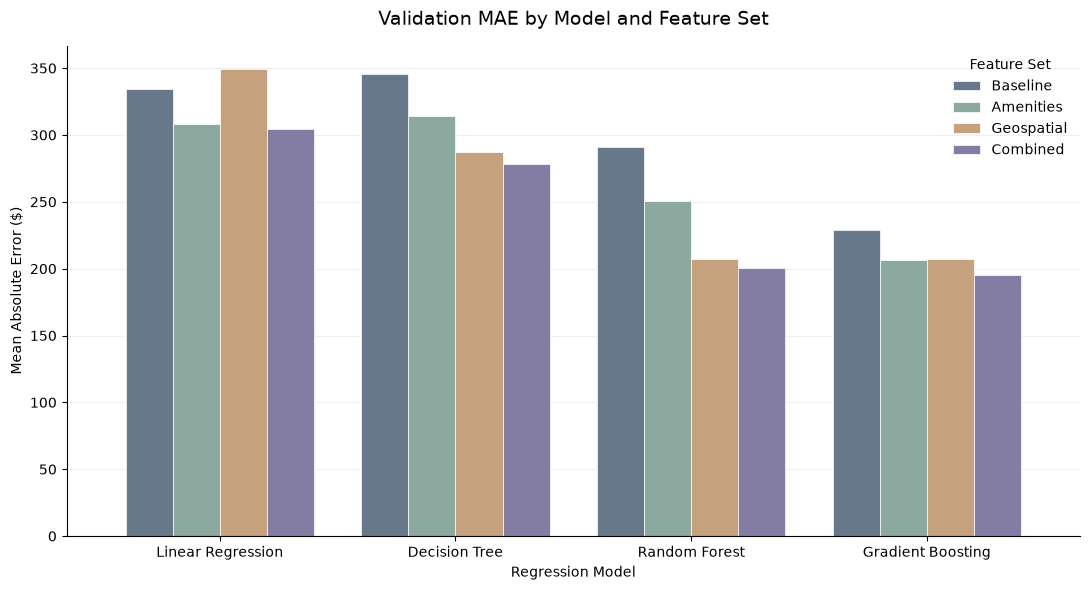

In [56]:
import matplotlib.pyplot as plt

# Muted, professional color palette
feature_colors = {
    "Baseline": "#66788A",
    "Amenities": "#8CA9A0",
    "Geospatial": "#C5A27D",
    "Combined": "#847DA3"
}

# Prepare data for visualization
mae_plot = mae_comparison.set_index("Model")[feature_columns]

fig, ax = plt.subplots(figsize=(11, 6))

mae_plot.plot(
    kind="bar",
    ax=ax,
    color=[feature_colors[col] for col in feature_columns],
    width=0.8,
    edgecolor="white",
    linewidth=0.5
)

ax.set_title(
    "Validation MAE by Model and Feature Set",
    fontsize=14,
    pad=15
)
ax.set_xlabel("Regression Model")
ax.set_ylabel("Mean Absolute Error ($)")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

# Subtle horizontal grid
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    title="Feature Set",
    frameon=False,
    loc="upper right"
)

plt.tight_layout()
plt.show()


### 7.2. Relative Improvement in MAE

To quantify the contribution of each feature set, we calculate the percentage reduction in validation MAE relative to the corresponding baseline model.

A positive percentage indicates an improvement in predictive accuracy, while a negative percentage indicates that the additional predictors increased prediction error.

Because the regression algorithm and hyperparameters remain fixed within each comparison, these results help assess the incremental predictive value of amenities, geospatial characteristics, and their combination.

These comparisons describe predictive performance rather than causal effects of individual features.


In [55]:
# Percentage reduction in MAE relative to each model's baseline
mae_improvement = mae_comparison[["Model"]].copy()

for feature_set in ["Amenities", "Geospatial", "Combined"]:
    mae_improvement[f"{feature_set} Improvement (%)"] = (
        (mae_comparison["Baseline"] - mae_comparison[feature_set])
        / mae_comparison["Baseline"]
        * 100
    )

display(mae_improvement.round(2))


,Model,Amenities Improvement (%),Geospatial Improvement (%),Combined Improvement (%)
0,Linear Regression,7.88,-4.41,9.09
1,Decision Tree,9.12,16.92,19.59
2,Random Forest,13.99,28.82,31.25
3,Gradient Boosting,9.86,9.58,14.68


#### 7.2.1. Interpretation of Relative MAE Improvements

The relative improvements in validation MAE reveal important differences in how regression algorithms benefit from additional predictors.

**Random Forest exhibits the largest improvement**, achieving a 31.25% reduction in MAE with the combined feature set. Geospatial variables alone account for a substantial improvement (28.82%), suggesting that neighborhood accessibility and proximity characteristics provide valuable predictive information for this model.

**Gradient Boosting benefits from both feature groups.** Amenities and geospatial variables individually reduce MAE by 9.86% and 9.58%, respectively. Combining them increases the reduction to 14.68%, producing the lowest absolute MAE ($195.57) among all evaluated models.

**Decision Tree also benefits substantially from geospatial information**, achieving a 16.92% reduction in MAE with geospatial features and a 19.59% reduction with the combined set.

**Linear Regression behaves differently.** While amenities reduce MAE by 7.88%, geospatial variables alone increase prediction error by 4.41%. Nevertheless, combining both groups produces a 9.09% improvement relative to the baseline.

Overall, the results indicate that the predictive value of additional features depends on the regression algorithm. Tree-based models, particularly Random Forest, benefit substantially from geospatial information, while Gradient Boosting achieves the strongest absolute predictive performance.

These findings describe improvements in validation performance and should not be interpreted as causal effects of individual property or neighborhood characteristics.


### 7.3. RMSE Comparison

We compare validation RMSE across the four regression algorithms and feature configurations.

Lower RMSE indicates better predictive performance. We report the RMSE values, visualize the differences, and calculate percentage reductions relative to each model's baseline.


In [60]:
# 1. RMSE comparison table
rmse_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],
    "Baseline": [551.74, 533.11, 464.58, 396.24],
    "Amenities": [
        linear_rmse, tree_rmse, rf_rmse, gb_rmse
    ],
    "Geospatial": [
        linear_geo_rmse, tree_geo_rmse,
        rf_geo_rmse, gb_geo_rmse
    ],
    "Combined": [
        linear_combined_rmse, tree_combined_rmse,
        rf_combined_rmse, gb_combined_rmse
    ]
}).set_index("Model")

display(rmse_comparison.round(2))


,Baseline,Amenities,Geospatial,Combined
Model,,,,
Linear Regression,551.74,518.90,562.92,512.00
Decision Tree,533.11,512.13,478.83,460.30
Random Forest,464.58,437.19,377.95,369.80
Gradient Boosting,396.24,371.76,371.23,361.24


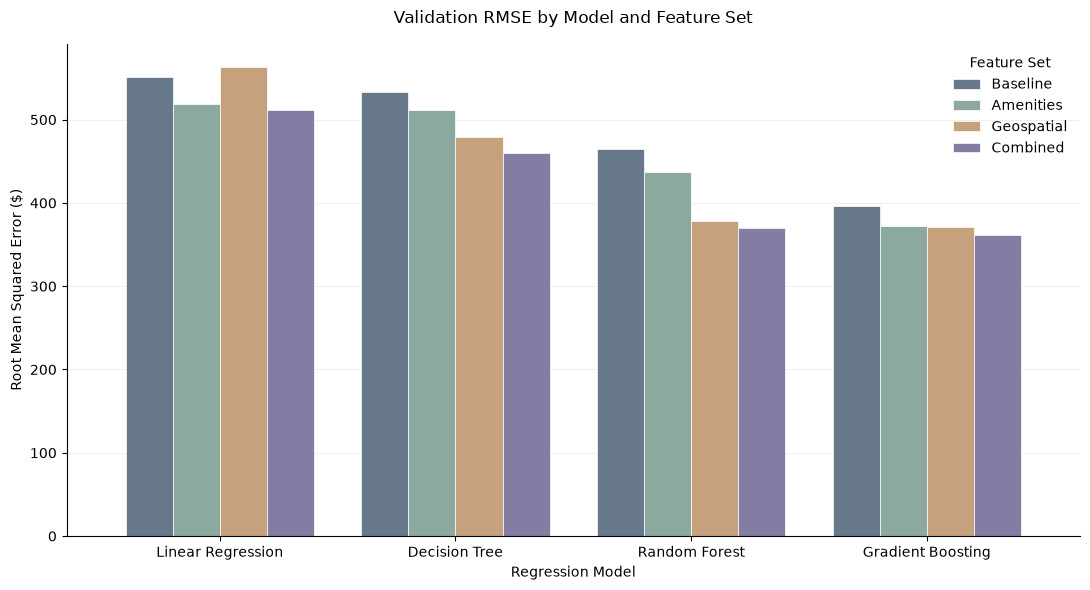

,Amenities Improvement (%),Geospatial Improvement (%),Combined Improvement (%)
Model,,,
Linear Regression,5.95,-2.03,7.20
Decision Tree,3.94,10.18,13.66
Random Forest,5.90,18.65,20.40
Gradient Boosting,6.18,6.31,8.83


In [61]:
# 2. RMSE comparison chart
ax = rmse_comparison.plot(
    kind="bar",
    figsize=(11, 6),
    color=[feature_colors[col] for col in feature_columns],
    width=0.8,
    edgecolor="white",
    linewidth=0.5
)

ax.set_title("Validation RMSE by Model and Feature Set", pad=15)
ax.set_xlabel("Regression Model")
ax.set_ylabel("Root Mean Squared Error ($)")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(title="Feature Set", frameon=False)

plt.tight_layout()
plt.show()

# 3. Percentage reduction in RMSE relative to baseline
rmse_improvement = pd.DataFrame(index=rmse_comparison.index)

for feature_set in ["Amenities", "Geospatial", "Combined"]:
    rmse_improvement[f"{feature_set} Improvement (%)"] = (
        (rmse_comparison["Baseline"] - rmse_comparison[feature_set])
        / rmse_comparison["Baseline"] * 100
    )

display(rmse_improvement.round(2))


#### 7.3.1. Interpretation of RMSE Results

The RMSE results are consistent with the MAE findings: the combined feature set achieves the lowest prediction error across all four regression algorithms.

**Gradient Boosting achieves the best overall RMSE ($361.24)**, followed by Random Forest ($369.80). Random Forest shows the largest relative improvement over its baseline, with a reduction of approximately 20.4%.

Geospatial features substantially improve the performance of tree-based models but slightly worsen Linear Regression when used alone.

Overall, the results reinforce the value of combining amenity and geospatial information, particularly for ensemble models.


### 7.4. R² Comparison

We compare validation $R^2$ across the four regression algorithms and feature configurations.

Higher $R^2$ values indicate better predictive performance. We report the values, visualize the differences, and calculate percentage improvements relative to each model's baseline.


,Baseline,Amenities,Geospatial,Combined
Model,,,,
Linear Regression,0.6764,0.7138,0.6631,0.7213
Decision Tree,0.6979,0.7212,0.7563,0.7748
Random Forest,0.7706,0.7968,0.8481,0.8546
Gradient Boosting,0.8331,0.8531,0.8535,0.8613


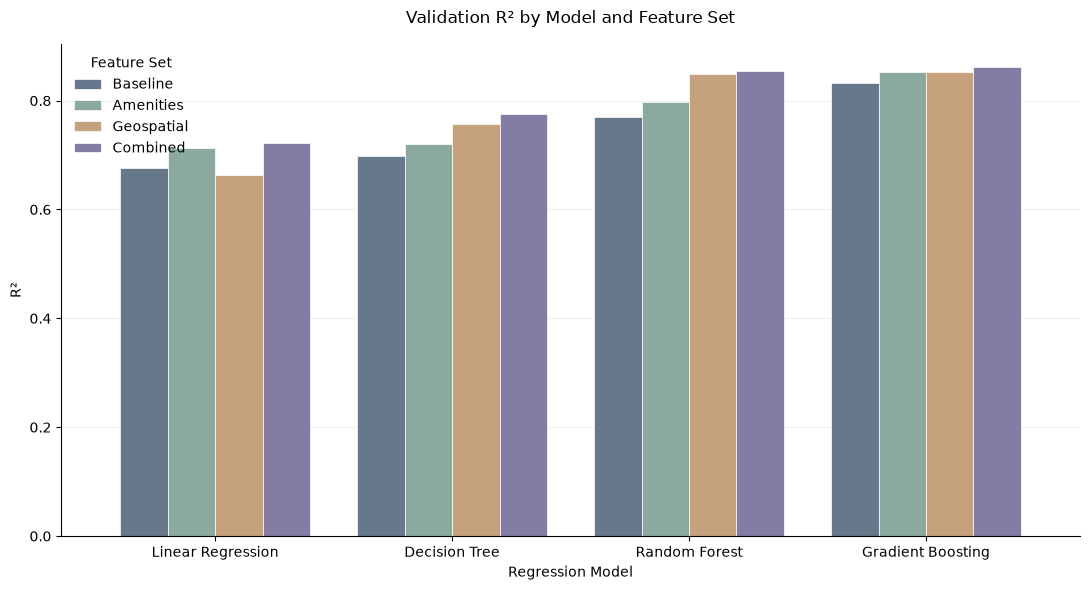

,Amenities Improvement (%),Geospatial Improvement (%),Combined Improvement (%)
Model,,,
Linear Regression,5.52,-1.96,6.64
Decision Tree,3.34,8.36,11.01
Random Forest,3.40,10.06,10.90
Gradient Boosting,2.40,2.45,3.38


In [62]:
# 1. R² comparison table
r2_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],
    "Baseline": [0.6764, 0.6979, 0.7706, 0.8331],
    "Amenities": [
        linear_r2, tree_r2, rf_r2, gb_r2
    ],
    "Geospatial": [
        linear_geo_r2, tree_geo_r2,
        rf_geo_r2, gb_geo_r2
    ],
    "Combined": [
        linear_combined_r2, tree_combined_r2,
        rf_combined_r2, gb_combined_r2
    ]
}).set_index("Model")

display(r2_comparison.round(4))

# 2. R² comparison chart
ax = r2_comparison.plot(
    kind="bar",
    figsize=(11, 6),
    color=[feature_colors[col] for col in feature_columns],
    width=0.8,
    edgecolor="white",
    linewidth=0.5
)

ax.set_title("Validation R² by Model and Feature Set", pad=15)
ax.set_xlabel("Regression Model")
ax.set_ylabel("R²")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(title="Feature Set", frameon=False)

plt.tight_layout()
plt.show()

# 3. Percentage improvement relative to baseline
r2_improvement = pd.DataFrame(index=r2_comparison.index)

for feature_set in ["Amenities", "Geospatial", "Combined"]:
    r2_improvement[f"{feature_set} Improvement (%)"] = (
        (r2_comparison[feature_set] - r2_comparison["Baseline"])
        / r2_comparison["Baseline"] * 100
    )

display(r2_improvement.round(2))


#### 7.4.1. Interpretation of R² Results

The $R^2$ results confirm that the combined feature set achieves the best predictive performance across all four regression algorithms.

**Gradient Boosting achieves the highest $R^2$ (0.8613)**, followed by Random Forest (0.8546). Decision Tree exhibits the largest relative increase in $R^2$ (11.01%), closely followed by Random Forest (10.90%).

Geospatial features improve the explanatory power of tree-based models but reduce the performance of Linear Regression when used alone.

Overall, these findings are consistent with the MAE and RMSE comparisons and support the selection of Gradient Boosting with combined features as the leading candidate.


### 7.5. MdAPE Comparison

We compare Median Absolute Percentage Error (MdAPE) across the four regression algorithms and feature configurations.

MdAPE measures the median absolute prediction error relative to the observed rental price, expressed as a percentage. Lower values indicate better predictive performance.

We report the MdAPE values, visualize the differences, and calculate percentage reductions relative to each model's baseline.


,Baseline,Amenities,Geospatial,Combined
Model,,,,
Linear Regression,13.57,12.39,14.58,12.31
Decision Tree,14.25,12.11,11.63,11.11
Random Forest,11.46,9.00,7.45,7.06
Gradient Boosting,8.52,7.45,7.62,7.07


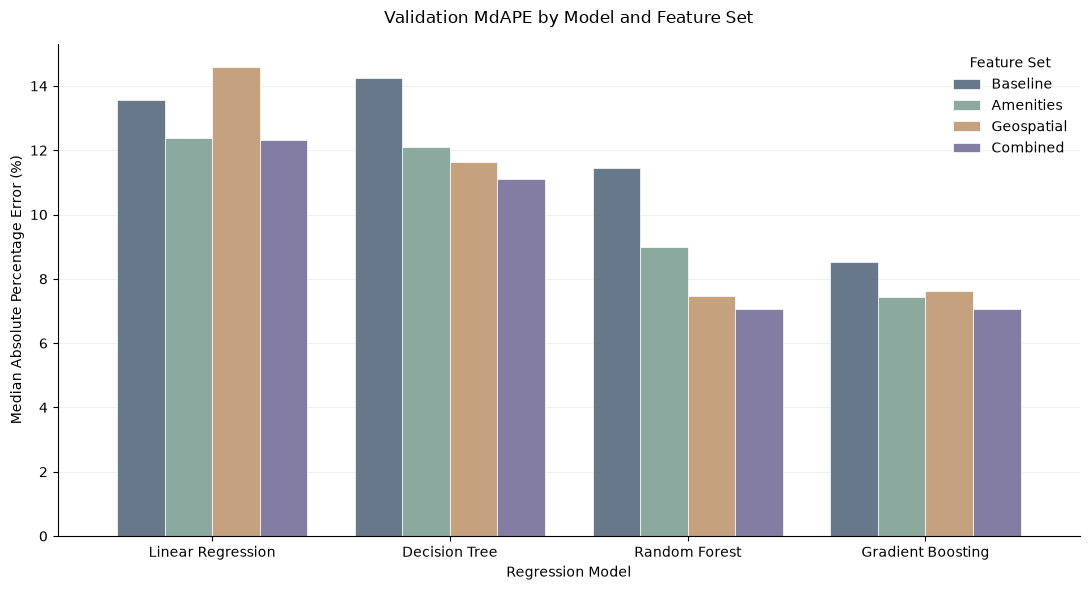

,Amenities Improvement (%),Geospatial Improvement (%),Combined Improvement (%)
Model,,,
Linear Regression,8.69,-7.45,9.26
Decision Tree,15.01,18.38,22.02
Random Forest,21.47,34.97,38.42
Gradient Boosting,12.60,10.56,17.03


In [63]:
# 1. MdAPE comparison table
mdape_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],
    "Baseline": [13.57, 14.25, 11.46, 8.52],
    "Amenities": [
        linear_mdape, tree_mdape, rf_mdape, gb_mdape
    ],
    "Geospatial": [
        linear_geo_mdape, tree_geo_mdape,
        rf_geo_mdape, gb_geo_mdape
    ],
    "Combined": [
        linear_combined_mdape, tree_combined_mdape,
        rf_combined_mdape, gb_combined_mdape
    ]
}).set_index("Model")

display(mdape_comparison.round(2))

# 2. MdAPE comparison chart
ax = mdape_comparison.plot(
    kind="bar",
    figsize=(11, 6),
    color=[feature_colors[col] for col in feature_columns],
    width=0.8,
    edgecolor="white",
    linewidth=0.5
)

ax.set_title("Validation MdAPE by Model and Feature Set", pad=15)
ax.set_xlabel("Regression Model")
ax.set_ylabel("Median Absolute Percentage Error (%)")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(title="Feature Set", frameon=False)

plt.tight_layout()
plt.show()

# 3. Percentage reduction relative to baseline
mdape_improvement = pd.DataFrame(index=mdape_comparison.index)

for feature_set in ["Amenities", "Geospatial", "Combined"]:
    mdape_improvement[f"{feature_set} Improvement (%)"] = (
        (mdape_comparison["Baseline"] - mdape_comparison[feature_set])
        / mdape_comparison["Baseline"] * 100
    )

display(mdape_improvement.round(2))


#### 7.5.1. Interpretation of MdAPE Results

The MdAPE results confirm that combining amenity and geospatial features improves predictive performance across all four regression algorithms.

**Random Forest achieves the lowest MdAPE (7.06%)**, narrowly outperforming Gradient Boosting (7.07%). It also exhibits the largest relative reduction in MdAPE (38.42%) compared with its baseline.

The combined feature set produces the lowest MdAPE for every model, reinforcing the findings from the other evaluation metrics.

Overall, Gradient Boosting remains the preferred model based on MAE, RMSE, and $R^2$, while Random Forest provides nearly identical performance in terms of median percentage error.
